# Audit et EDA de la table de modélisation

**Contributeurs :** Cécile NAUDET, Théophyle CHEVET, Gabrielle RICHERT, Christian BAYILI· **Date :** 31/10/2026, regroupé le 05/11/2026

Table produite à la fin du feature engineering (`table_modelisation_bv.parquet`) : une ligne par année × sous-bassin × type de bien, seulement les lignes où le prix et le prix N-1 sont renseignés.

**Ce notebook se relance à chaque changement de la table** (variable ajoutée ou retirée, nouvelle source, correctif). Il ne contient que la méthode :
- chaque section donne le code, puis **« Comment lire »** : ce que mesure le résultat et comment l'interpréter ;
- les résultats ne sont pas commentés dans le corps du notebook : ils changent à chaque passage ;
- **la synthèse, en fin de notebook, garde l'historique** : pour chaque passage, la date, l'état de la table et les enseignements tirés, avec la suite donnée.

Pour un nouveau passage : relancer tout le notebook, compléter la description des nouvelles variables (section 2) si le notebook le demande, puis ajouter un passage daté à la synthèse.

Sections :
1. Contenu de la table
2. Nature des variables
3. Distributions et passage en log
4. Redondances entre variables
5. La cible et le prix de l'année précédente
6. Liens avec le prix
7. D'où viennent les écarts de prix : niveau des territoires, tendance commune, évolution propre
8. Importance des variables
9. Variables qui ne comptent dans aucun modèle
10. Densité de population
11. ACP, version simple
12. ACP, version complète

### Imports, chargement de la table et listes communes

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

# config.py se trouve à la racine du projet : on remonte les dossiers jusqu'à le trouver
racine = Path.cwd()
while not (racine / "config.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine))
from config import DATA_OUT

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Table lue par commun.py : index annee x sous_bassin_de_vie x type_bien (annee aussi en colonne)
table = pd.read_parquet(DATA_OUT / "table_modelisation_bv.parquet")

# Version « à plat » : sous-bassin et type de bien remis en colonnes, pour les sections qui en ont besoin
plat = table.reset_index(level=["sous_bassin_de_vie", "type_bien"]).reset_index(drop=True)

CIBLE = "prix"
HORS_MODELE = ["annee", "n_ventes", "BV2022"]          # jamais des variables explicatives
# Variables de contrôle qualité : elles décrivent la fiabilité d'une source, pas le territoire
CONTROLE = [c for c in ["part_indicateurs_estimes", "part_logements_taux_impute",
                        "part_menages_couverts", "part_emploi_secret"] if c in table.columns]
ANNEE_VALIDATION = 2024                                 # 2025 : année de test, jamais regardée ici
print(table.shape, "| contrôle qualité :", CONTROLE)

(28450, 39) | contrôle qualité : ['part_indicateurs_estimes', 'part_logements_taux_impute', 'part_menages_couverts']


## 1. Contenu de la table



On charge la table et on regarde, pour chaque variable, son type, sa part de valeurs vides et son nombre de valeurs distinctes. Une variable qui n'a qu'une seule valeur, ou très peu, se repère tout de suite.

In [2]:
print(table.shape)
print("Index :", table.index.names, "| unique :", table.index.is_unique)

# Lignes par année et par type de bien
display(table.groupby(level=["annee", "type_bien"]).size().unstack())

# Une ligne par variable : type, part de valeurs vides, nombre de valeurs distinctes
apercu = pd.DataFrame({
    "type": table.dtypes.astype(str),
    "% vides": table.isna().mean().mul(100).round(1),
    "valeurs distinctes": table.nunique(),
})
display(apercu)

(28450, 39)
Index : ['annee', 'sous_bassin_de_vie', 'type_bien'] | unique : True


type_bien,appartement,maison
annee,,
2015,691,1769
2016,717,1775
2017,746,1776
2018,774,1780
2019,805,1780
2020,857,1780
2021,878,1781
2022,912,1782
2023,861,1781


,type,% vides,valeurs distinctes
annee,int64,0.0,11
maison,int64,0.0,2
n_ventes,int64,0.0,1757
nb_ventes_n1,float64,0.0,1737
prix,float64,0.0,4683
part_indicateurs_estimes,float64,17.4,15336
taux3_vols_vehicules,float64,17.4,16283
taux3_vols_violents,float64,17.4,15655
taux3_vols_sans_violence,float64,17.4,16282
taux3_cambriolages,float64,17.4,16280


**Comment lire**
- **Lignes par année et par type de bien** : environ un sous-bassin sur deux n'atteint pas 20 ventes d'appartements par an ; un saut d'une année à l'autre signale un changement de la table (seuil, découpage) à expliquer.
- **% vides** : une variable vide pour certaines années seulement vient d'une source qui commence plus tard (décalage d'un an, fenêtre de lissage) ; une variable vide pour quelques sous-bassins vient d'une donnée absente localement. Les deux sont à expliquer dans la synthèse.
- **Valeurs distinctes** : une photo fixe (une valeur par sous-bassin, identique toutes les années) a environ autant de valeurs distinctes que de sous-bassins ; une variable qui varie dans le temps en a beaucoup plus ; très peu de valeurs signale beaucoup de zéros ou un arrondi.

## 2. Nature des variables : nombre ou taux, et base de calcul



Pour chaque variable : sa source, sa nature (nombre, taux, part, moyenne, prix) et sa base de calcul, relues dans le code du feature engineering. Un nombre suit d'abord la taille du sous-bassin ; un taux ou une part permet de comparer des territoires de tailles différentes.

Si une variable de la table n'est pas décrite, le notebook s'arrête : il faut l'ajouter au dictionnaire `nature` avant de continuer.

In [3]:
# Pour chaque variable : (source, nature, base de calcul)
nature = {}

# DVF+ : année, type de bien, ventes, prix
nature["annee"]        = ("DVF+", "année", "année des prix (N)")
nature["maison"]       = ("DVF+", "indicatrice", "1 = maison, 0 = appartement")
nature["n_ventes"]     = ("DVF+", "nombre", "ventes de l'année N (sert seulement au seuil de 20 ventes)")
nature["nb_ventes_n1"] = ("DVF+", "nombre", "ventes de l'année N-1, additionnées au sous-bassin")
nature["prix"]         = ("DVF+", "prix (€/m²)", "médiane des prix au m² des ventes de N")
nature["prix_n1"]      = ("DVF+", "prix (€/m²)", "médiane des prix au m² des ventes de N-1")

# Délinquance (SSMSI) : faits et dénominateurs additionnés au sous-bassin, puis taux lissé sur 3 ans
FAMILLES = ["vols_vehicules", "vols_violents", "vols_sans_violence", "cambriolages",
            "stupefiants", "violences_intrafamiliales", "violences_sexuelles"]
for f in FAMILLES:
    denom = "1 000 logements" if f == "cambriolages" else "1 000 habitants"
    nature["taux3_" + f] = ("Délinquance", "taux",
        f"faits de N-3 à N-1 pour {denom} des mêmes années (1 an pour les prix 2017, 2 ans pour 2018)")
nature["part_indicateurs_estimes"] = ("Délinquance", "part (%), contrôle qualité",
    "indicateurs estimés (secret statistique) sur 15, moyenne pondérée par la population")

# LOVAC (photo 2023)
nature["taux_vacance_complete"] = ("LOVAC", "taux (%)",
    "taux communal (complété par l'EPCI si masqué), moyenne pondérée par les logements du recensement (P22_LOG)")
nature["part_logements_taux_impute"] = ("LOVAC", "part (%), contrôle qualité",
    "logements situés dans une commune dont le taux a été complété par l'EPCI / P22_LOG")

# Équipements (BPE 2025, photo) : équipements et habitants 2024 additionnés au sous-bassin
for dom in ["commerces", "sante", "services", "sports", "tourisme", "transports"]:
    nature["taux_equip_" + dom] = ("Équipements", "taux", "équipements du domaine pour 10 000 habitants (2024)")

# Densité (photo) : habitants 2024 et superficie additionnés au sous-bassin
nature["densite_population"] = ("Densité", "taux",
    "habitants 2024 / km² (arrondissements : superficie réelle de chaque arrondissement)")

# Parc de logements (recensement 2022, photo) : effectifs additionnés au sous-bassin, puis formule
LOGEMENT = {
    "taux_vacance":       ("part (%)", "P22_LOGVAC / P22_LOG"),
    "part_rsec":          ("part (%)", "P22_RSECOCC / P22_LOG"),
    "part_apparts":       ("part (%)", "P22_APPART / P22_LOG"),
    "log_nb_logements":   ("log d'un nombre", "log10(P22_LOG)"),
    "part_moins40m2":     ("part (%)", "(P22_RP_M30M2 + P22_RP_3040M2) / P22_RP"),
    "part_avant1946":     ("part (%)", "(P22_RP_ACH1919 + P22_RP_ACH1945) / P22_RP"),
    "part_2006_2019":     ("part (%)", "P22_RP_ACH2019 / P22_RP"),
    "anciennete_moyenne": ("moyenne", "P22_ANEM_RP / P22_RP"),
    "part_sans_voiture":  ("part (%)", "100 - P22_RP_VOIT1P / P22_MEN"),
}
for var, (nat, formule) in LOGEMENT.items():
    nature[var] = ("Logement", nat, formule)

# Ménages (recensements 2019 à 2022, une valeur par année) : effectifs additionnés au sous-bassin, puis formule
# 2023 = 2022 ; 2024 = 2022 + évolution 2020-2022 bornée ; prix 2015-2018 : 2019 ; prix 2025 : 2024
MENAGES = {
    "taux_personnes_seules_pct_men":        ("part (%)", "C_MENPSEUL / C_MEN"),
    "part_familles_monoparentales_pct_fam": ("part (%)", "C_FAMMONO / C_FAM"),
    "part_familles_nombreuses_pct_fam":     ("part (%)", "(C_NE24F3 + C_NE24F4P) / C_FAM"),
    "part_couples_sans_enfants_pct_fam":    ("part (%)", "C_COUPSENF / C_FAM"),
}
for var, (nat, formule) in MENAGES.items():
    nature[var] = ("Ménages", nat, formule)

# Filosofi (photo 2021)
nature["niveau_vie_median"] = ("Filosofi", "moyenne (€)",
    "médianes communales, moyenne pondérée par les ménages fiscaux (communes à médiane connue)")
nature["part_menages_couverts"] = ("Filosofi", "part (%), contrôle qualité",
    "ménages fiscaux des communes à médiane connue / ménages du recensement 2022 (P22_MEN)")

# Emploi salarié privé (Urssaf) : exporté par le feature engineering, pas encore dans la table
nature["emploi_par_logement"] = ("Emploi", "taux", "salariés du privé au 31/12 de N-1 / logements du recensement 2022")
nature["evol_emploi_n2_n1"] = ("Emploi", "évolution (%)", "salariés du 31/12 de N-2 au 31/12 de N-1, à champ constant")
nature["part_emploi_secret"] = ("Emploi", "part (%), contrôle qualité", "cellules commune × activité sous secret statistique")

# Identifiant
nature["BV2022"] = ("Liaison", "identifiant",
    "bassin de vie du sous-bassin, pour le bootstrap du test contre la naïve (jamais une variable explicative)")

# Contrôle : toute variable de la table doit être décrite
non_decrites = sorted(set(table.columns) - set(nature))
assert not non_decrites, f"Variables à décrire dans le dictionnaire nature : {non_decrites}"
print("Décrites mais absentes de cette table :", sorted(set(nature) - set(table.columns)))

nature_vars = pd.DataFrame.from_dict({v: nature[v] for v in table.columns}, orient="index",
                                     columns=["source", "nature", "base de calcul"])
display(nature_vars)
display(pd.crosstab(nature_vars["source"], nature_vars["nature"]))

Décrites mais absentes de cette table : ['emploi_par_logement', 'evol_emploi_n2_n1', 'part_emploi_secret']


,source,nature,base de calcul
annee,DVF+,année,année des prix (N)
maison,DVF+,indicatrice,"1 = maison, 0 = appartement"
n_ventes,DVF+,nombre,ventes de l'année N (sert seulement au seuil d...
nb_ventes_n1,DVF+,nombre,"ventes de l'année N-1, additionnées au sous-ba..."
prix,DVF+,prix (€/m²),médiane des prix au m² des ventes de N
part_indicateurs_estimes,Délinquance,"part (%), contrôle qualité",indicateurs estimés (secret statistique) sur 1...
taux3_vols_vehicules,Délinquance,taux,faits de N-3 à N-1 pour 1 000 habitants des mê...
taux3_vols_violents,Délinquance,taux,faits de N-3 à N-1 pour 1 000 habitants des mê...
taux3_vols_sans_violence,Délinquance,taux,faits de N-3 à N-1 pour 1 000 habitants des mê...
taux3_cambriolages,Délinquance,taux,faits de N-3 à N-1 pour 1 000 logements des mê...


nature,année,identifiant,indicatrice,log d'un nombre,moyenne,moyenne (€),nombre,part (%),"part (%), contrôle qualité",prix (€/m²),taux,taux (%)
source,,,,,,,,,,,,
DVF+,1,0,1,0,0,0,2,0,0,2,0,0
Densité,0,0,0,0,0,0,0,0,0,0,1,0
Délinquance,0,0,0,0,0,0,0,0,1,0,7,0
Filosofi,0,0,0,0,0,1,0,0,1,0,0,0
LOVAC,0,0,0,0,0,0,0,0,1,0,0,1
Liaison,0,1,0,0,0,0,0,0,0,0,0,0
Logement,0,0,0,1,1,0,0,7,0,0,0,0
Ménages,0,0,0,0,0,0,0,4,0,0,0,0
Équipements,0,0,0,0,0,0,0,0,0,0,6,0


**Comment lire**
- **Une seule variable par information** : pour chaque source, la table doit contenir des taux, des parts ou des moyennes plutôt que des nombres, sauf raison particulière (par exemple `nb_ventes_n1`, ou `log_nb_logements` qui porte volontairement la taille du territoire).
- **Contrôle qualité** : ces variables mesurent la fiabilité d'une source ; elles restent hors des modèles et servent à l'analyse des erreurs.
- **« Décrites mais absentes »** : variables prévues (une source pas encore branchée) ou retirées à un passage précédent.

## 3. Distributions, valeurs extrêmes et passage en log



Sur toutes les lignes de la table, telles que le modèle les verra. Pour chaque variable : quelques centiles, le rapport entre le maximum et le 99e centile, et l'asymétrie.

,min,1%,5%,50%,95%,99%,max,max / p99,asymetrie
n_ventes,20.00,22.00,32.00,153.00,796.00,2507.61,70042.00,27.93,33.56
nb_ventes_n1,20.00,22.00,31.00,148.00,784.55,2492.51,70042.00,28.10,33.77
prix,350.00,692.49,882.00,1811.00,4340.55,7490.00,19652.00,2.62,3.45
part_indicateurs_estimes,0.00,0.00,6.67,47.81,64.16,68.68,78.84,1.15,-1.06
taux3_vols_vehicules,0.33,0.77,1.19,3.21,10.26,18.21,69.87,3.84,5.04
taux3_vols_violents,0.00,0.00,0.05,0.22,1.53,5.35,44.25,8.28,14.23
taux3_vols_sans_violence,0.39,1.58,2.13,4.41,15.94,49.05,570.18,11.62,19.40
taux3_cambriolages,0.22,0.91,1.62,4.82,10.81,14.17,27.64,1.95,1.19
taux3_stupefiants,0.00,0.48,0.76,2.27,6.91,12.08,149.54,12.38,13.63
taux3_violences_intrafamiliales,0.15,0.50,0.77,1.92,3.99,5.19,10.51,2.02,1.12


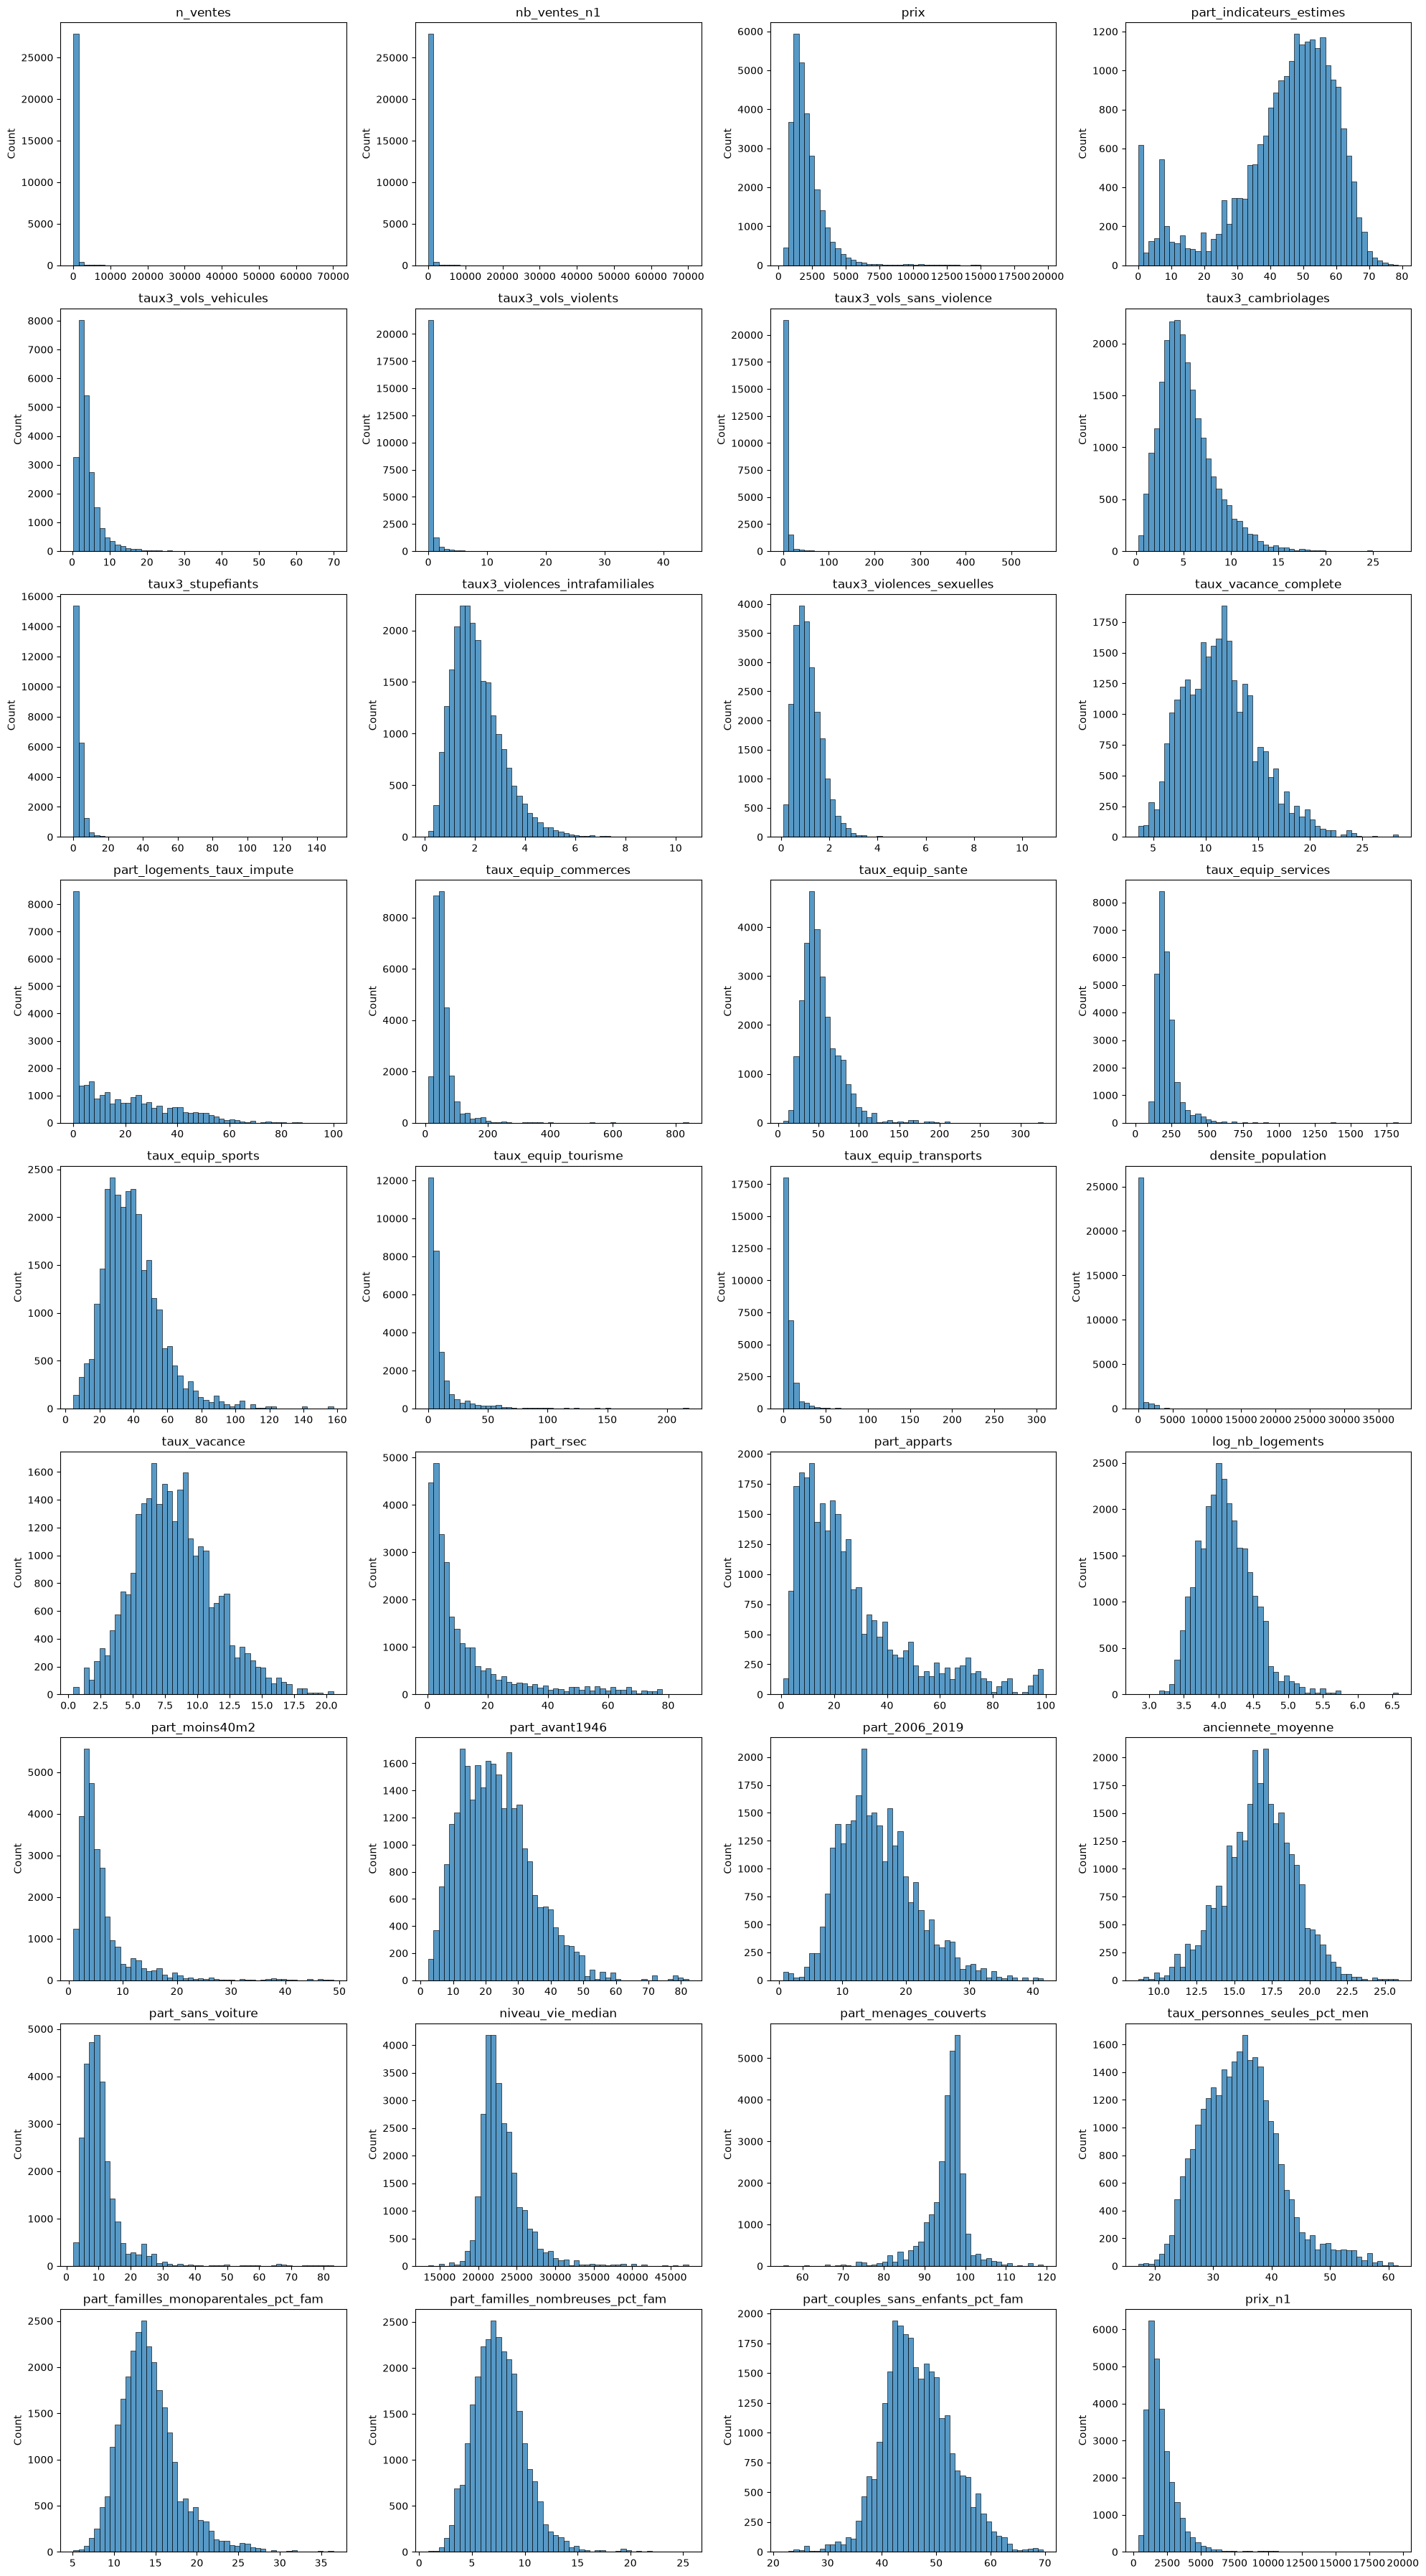

In [4]:
# Toutes les variables numériques, sauf l'année, l'indicatrice maison et l'identifiant BV2022
variables = [c for c in table.columns if c not in ["annee", "maison", "BV2022"]]

# 1. Centiles, valeurs extrêmes et asymétrie
quantiles = table[variables].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T
quantiles["max / p99"] = quantiles["max"] / quantiles["99%"]
quantiles["asymetrie"] = table[variables].skew()
display(quantiles[["min", "1%", "5%", "50%", "95%", "99%", "max", "max / p99", "asymetrie"]].round(2))

# 2. Histogrammes de toutes les variables (4 par ligne)
n_lignes = -(-len(variables) // 4)          # division arrondie au-dessus
fig, axes = plt.subplots(n_lignes, 4, figsize=(20, 4 * n_lignes))
axes = axes.flatten()
for ax, col in zip(axes, variables):
    sns.histplot(table[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes[len(variables):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Comment lire**
- **max / p99** : proche de 1, le maximum reste dans la continuité des autres valeurs ; nettement au-dessus de 1, quelques valeurs isolées tirent la distribution. Il faut alors vérifier s'il s'agit de territoires réels (Paris, centres touristiques) ou d'erreurs.
- **Asymétrie** : autour de 0, distribution symétrique ; au-delà de 1, longue queue vers les grandes valeurs ; en dessous de −1, longue queue vers les petites valeurs.
- **Règle retenue** : une variable dont l'asymétrie dépasse 1 est passée en log avant une régression linéaire, une ACP ou un réseau de neurones ; inutile pour les arbres, qui ne regardent que l'ordre des valeurs.

### Passage en log des variables asymétriques
Liste calculée à chaque passage : log(x) pour une variable toujours positive, log(1 + x) si elle contient des zéros ; pas de log si elle contient des valeurs négatives (une évolution, par exemple). Le prix et le prix N-1 sont traités à part, dans les notebooks de modélisation. Transformation faite sur une copie de la table, pour l'exploration : elle n'est pas exportée.

In [5]:
SEUIL_ASYMETRIE = 1

# Variables candidates : toutes, sauf la cible, le prix N-1, l'indicatrice, les variables hors modèle et le contrôle qualité
candidates = [c for c in table.columns if c not in [CIBLE, "prix_n1", "maison"] + HORS_MODELE + CONTROLE]
asymetrie = table[candidates].skew()
a_transformer = list(asymetrie[asymetrie > SEUIL_ASYMETRIE].index)

LOG = [c for c in a_transformer if table[c].min() > 0]       # toujours positives : log(x)
LOG1P = [c for c in a_transformer if table[c].min() == 0]    # avec des zéros : log(1 + x)
SANS_LOG = [c for c in a_transformer if table[c].min() < 0]  # valeurs négatives : pas de log
print(len(LOG), "en log :", LOG)
print(len(LOG1P), "en log(1 + x) :", LOG1P)
print("Asymétriques mais avec des valeurs négatives :", SANS_LOG)


def passer_en_log(donnees):
    """Applique log(x) aux variables de LOG et log(1 + x) à celles de LOG1P, si elles sont présentes."""
    x = donnees.copy()
    for c in x.columns:
        if c in LOG:
            x[c] = np.log(x[c])
        elif c in LOG1P:
            x[c] = np.log1p(x[c])
    return x


table_log = passer_en_log(table)

# Asymétrie avant et après
asym = pd.DataFrame({"avant": table[LOG + LOG1P].skew(), "après": table_log[LOG + LOG1P].skew()}).round(2)
display(asym.sort_values("avant", ascending=False))

17 en log : ['nb_ventes_n1', 'taux3_vols_vehicules', 'taux3_vols_sans_violence', 'taux3_cambriolages', 'taux3_violences_intrafamiliales', 'taux3_violences_sexuelles', 'taux_equip_commerces', 'taux_equip_sante', 'taux_equip_services', 'taux_equip_sports', 'densite_population', 'part_rsec', 'part_apparts', 'part_moins40m2', 'part_sans_voiture', 'niveau_vie_median', 'part_familles_monoparentales_pct_fam']
4 en log(1 + x) : ['taux3_vols_violents', 'taux3_stupefiants', 'taux_equip_tourisme', 'taux_equip_transports']
Asymétriques mais avec des valeurs négatives : []


,avant,après
nb_ventes_n1,33.77,0.52
taux3_vols_sans_violence,19.40,1.42
taux_equip_transports,14.65,0.16
taux3_vols_violents,14.23,3.66
taux3_stupefiants,13.63,0.80
densite_population,9.03,1.16
taux_equip_commerces,6.64,0.86
taux_equip_tourisme,5.50,0.71
taux_equip_services,5.22,1.07
taux3_vols_vehicules,5.04,0.35


**Comment lire**
- La colonne **après** doit revenir entre −1 et 1. Une variable qui reste au-dessus de 1 après le log garde quelques territoires très à part : à surveiller dans les modèles linéaires.
- Une variable juste au-dessus du seuil (asymétrie entre 1 et 1,2) passe en log par la règle, mais ce passage change peu de chose.
- **Interprétation d'une variable en log** : en régression, +1 % de la variable change le prix de (coefficient / 100) €/m² si le prix est en euros, de (coefficient) % si le prix est aussi en log ; pour un arbre, un seuil en log se relit avec l'exponentielle.

## 4. Redondances entre variables



**Pourquoi regarder cela :** deux variables qui portent la même information n'apportent rien de plus au modèle ; en régression linéaire, elles rendent même les coefficients instables. On n'en garde alors qu'une.

**Méthode :** corrélation de Spearman entre toutes les variables explicatives, sur toutes les lignes de la table. Spearman compare les classements : il n'est pas sensible aux valeurs extrêmes ni à une transformation en log. Seuil de redondance : |ρ| ≥ 0,8, comme dans l'EDA des sources. Hors calcul : la cible, les variables hors modèle et l'indicatrice `maison`.

On regarde aussi des couples à contrôler, liés par construction ou signalés dans le feature engineering.

In [6]:
# Variables explicatives : tout sauf la cible, les variables hors modèle et l'indicatrice maison
explicatives = [c for c in table.columns if c not in [CIBLE, "maison"] + HORS_MODELE]
rho = table[explicatives].corr(method="spearman")

# 1. Couples redondants : |rho| >= 0,8, du plus fort au moins fort (chaque couple une seule fois)
paires = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
paires.columns = ["variable 1", "variable 2", "rho"]
paires = paires.reindex(paires["rho"].abs().sort_values(ascending=False).index)
print("Couples à |rho| >= 0,8 :")
display(paires[paires["rho"].abs() >= 0.8].round(2))

# 2. Couples à contrôler (seuls ceux dont les deux variables sont dans la table)
A_CONTROLER = [
    ("taux_vacance", "taux_vacance_complete"),           # vacance : recensement / LOVAC
    ("densite_population", "log_nb_logements"),
    ("densite_population", "part_apparts"),
    ("part_familles_nombreuses_pct_fam", "taux_personnes_seules_pct_men"),
    ("emploi_par_logement", "densite_population"),
]
A_CONTROLER = [(a, b) for a, b in A_CONTROLER if a in rho.index and b in rho.index]
print("Couples à contrôler :")
display(pd.DataFrame([(a, b, round(rho.loc[a, b], 2)) for a, b in A_CONTROLER],
                     columns=["variable 1", "variable 2", "rho"]))

Couples à |rho| >= 0,8 :


,variable 1,variable 2,rho


Couples à contrôler :


,variable 1,variable 2,rho
0,taux_vacance,taux_vacance_complete,0.63
1,densite_population,log_nb_logements,0.46
2,densite_population,part_apparts,0.46
3,part_familles_nombreuses_pct_fam,taux_personnes_seules_pct_men,-0.27


**Comment lire (exemple fictif : deux variables à ρ = 0,9)**
- **Ce que mesure ρ** : on classe les sous-bassins selon la première variable, puis selon la seconde, et on compare les deux classements.
- **Le signe** : positif, les deux variables montent ensemble ; négatif, l'une monte quand l'autre baisse.
- **La valeur** : repères 0,1 lien faible, 0,3 moyen, 0,5 fort ; au-delà de 0,8, les deux variables portent presque la même information. Avec ρ = 0,9, les deux classements sont presque identiques : on n'en garde qu'une.
- **Quelle variable garder** : celle dont le lien avec le prix est le plus fort et le plus stable pour les deux types de bien (sections 6 et 8), à défaut la plus simple à expliquer. Le retrait se fait dans le feature engineering, puis le notebook est relancé (nouveau passage).
- **Couples à contrôler sous le seuil** : liés, mais chaque variable garde une information propre.

## 5. La cible et le prix de l'année précédente



On regarde la forme du prix au m² et son lien avec le prix de l'année précédente, qui sert de référence (prévision naïve). Années d'apprentissage seulement (2020 à 2023, comme `commun.py`) : 2024 et 2025 ne sont pas regardées.

maison : médiane = 1841.5 €/m² | asymétrie = 3.25 | en log : 0.33 | rho avec le prix N-1 = 0.988
   évolution médiane N-1 -> N par année (%) : {2020: 4.7, 2021: 7.7, 2022: 9.1, 2023: 0.8}
appartement : médiane = 2199.5 €/m² | asymétrie = 3.11 | en log : 0.47 | rho avec le prix N-1 = 0.985
   évolution médiane N-1 -> N par année (%) : {2020: 5.1, 2021: 7.5, 2022: 8.2, 2023: 2.9}


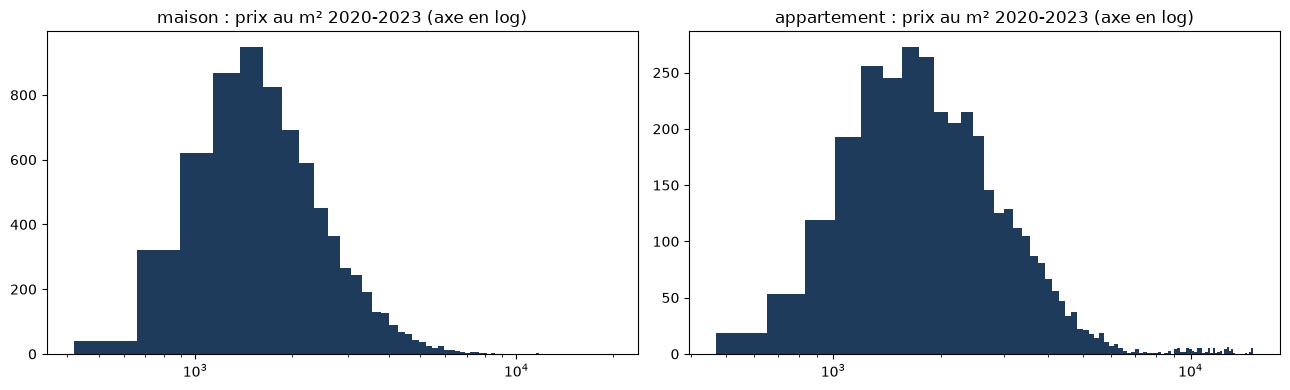

In [7]:
ANNEE_DEBUT = 2020          # première année d'apprentissage (comme commun.py)
apprentissage_plat = plat[(plat["annee"] >= ANNEE_DEBUT) & (plat["annee"] < ANNEE_VALIDATION)]

for type_bien in ["maison", "appartement"]:
    a = apprentissage_plat[apprentissage_plat["type_bien"] == type_bien]
    evolution = (a[CIBLE] / a["prix_n1"] - 1) * 100            # évolution N-1 -> N, en %
    print(type_bien, ": médiane =", a[CIBLE].median(), "€/m² | asymétrie =", round(a[CIBLE].skew(), 2),
          "| en log :", round(np.log(a[CIBLE]).skew(), 2),
          "| rho avec le prix N-1 =", round(stats.spearmanr(a[CIBLE], a["prix_n1"])[0], 3))
    print("   évolution médiane N-1 -> N par année (%) :", evolution.groupby(a["annee"]).median().round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, type_bien in zip(axes, ["maison", "appartement"]):
    prix = apprentissage_plat.loc[apprentissage_plat["type_bien"] == type_bien, CIBLE]
    ax.hist(prix, bins=80, color="#1f3b5c")
    ax.set_xscale("log")
    ax.set_title(f"{type_bien} : prix au m² {ANNEE_DEBUT}-{ANNEE_VALIDATION - 1} (axe en log)")
plt.tight_layout()
plt.show()

**Comment lire**
- **Asymétrie brute et en log** : si l'asymétrie du log est proche de 0, le prix est à modéliser en log dans une régression linéaire.
- **ρ avec le prix N-1** : proche de 1, le prix de l'année précédente donne déjà le niveau ; ce qui reste à prévoir, c'est l'évolution d'une année à l'autre, et la prévision naïve (prix N = prix N-1) sera difficile à battre.
- **Évolution médiane par année** : si toutes les années d'apprentissage vont dans le même sens et que l'année de validation va dans l'autre, un modèle qui a appris la tendance se trompera de sens.

## 6. Liens avec le prix



Corrélation de Spearman entre chaque variable du territoire et le prix, maisons et appartements séparés, sur les années d'apprentissage. On ajoute `part_logements_taux_impute` pour vérifier qu'une variable de contrôle n'est pas liée au prix.

In [8]:
# Variables du territoire : identiques pour les maisons et les appartements
TERRITOIRE = [c for c in plat.columns
              if c not in HORS_MODELE + CONTROLE + [CIBLE, "sous_bassin_de_vie", "type_bien", "maison", "prix_n1", "nb_ventes_n1"]]
print(len(TERRITOIRE), "variables du territoire")

a_tester = TERRITOIRE + ["nb_ventes_n1"] + [c for c in ["part_logements_taux_impute"] if c in plat.columns]
lignes = []
for v in a_tester:
    ligne = {"variable": v}
    for type_bien in ["maison", "appartement"]:
        a = apprentissage_plat[apprentissage_plat["type_bien"] == type_bien].dropna(subset=[v])
        ligne[type_bien] = round(stats.spearmanr(a[v], a[CIBLE])[0], 2)
    lignes.append(ligne)
liens = pd.DataFrame(lignes).set_index("variable")
display(liens.reindex(liens.abs().max(axis=1).sort_values(ascending=False).index))

29 variables du territoire


,maison,appartement
variable,,
part_avant1946,-0.76,-0.46
taux_vacance,-0.73,-0.61
anciennete_moyenne,-0.71,-0.46
niveau_vie_median,0.66,0.62
densite_population,0.64,0.40
part_2006_2019,0.62,0.35
taux_equip_sports,-0.61,-0.46
part_logements_taux_impute,-0.50,-0.47
taux_equip_transports,0.50,0.47


**Comment lire (exemple fictif : ρ = −0,7 pour les maisons)**
- **Le signe** : négatif, les sous-bassins où la variable est élevée ont plutôt des prix bas ; positif, plutôt des prix hauts.
- **La valeur** : repères 0,1 faible, 0,3 moyen, 0,5 fort. Avec −0,7, le lien est fort ; ρ² ≈ 0,49 : environ la moitié des écarts de classement des prix va avec cette variable.
- **Maisons et appartements** : un lien beaucoup plus fort pour un type de bien que pour l'autre confirme qu'il faut les modéliser séparément.
- **Ce n'est pas une cause** : une variable peut être liée au prix parce qu'elle signale un type de territoire (ville, campagne, littoral).
- **Variable de contrôle liée au prix** : elle mesure aussi le territoire (par exemple la ruralité), pas seulement la qualité de la donnée ; elle reste hors des modèles.

## 7. D'où viennent les écarts de prix : niveau des territoires, tendance commune, évolution propre



On découpe la variance du log du prix en trois parts, par type de bien, sur les années avant la validation :
1. **niveau des territoires** : écart entre la moyenne d'un sous-bassin et la moyenne générale ;
2. **tendance commune** : écart entre une année et la moyenne, la même pour tous les sous-bassins ;
3. **évolution propre** : ce qui reste, propre à un sous-bassin une année donnée.

In [9]:
d = plat[plat["annee"] < ANNEE_VALIDATION].dropna(subset=[CIBLE]).copy()
d["lp"] = np.log(d[CIBLE])

lignes = []
for t, g in d.groupby("type_bien"):
    total = g["lp"].var()
    r_zone = g["lp"] - g.groupby("sous_bassin_de_vie")["lp"].transform("mean")    # on retire le niveau du sous-bassin
    r_zone_an = r_zone - r_zone.groupby(g["annee"]).transform("mean")              # puis la tendance commune de l'année
    lignes.append({"type de bien": t,
                   "niveau des territoires": 1 - r_zone.var() / total,
                   "tendance commune (année)": (r_zone.var() - r_zone_an.var()) / total,
                   "évolution propre (sous-bassin × année)": r_zone_an.var() / total})
decomposition = (pd.DataFrame(lignes).set_index("type de bien") * 100).round(1)
print("Part de la variance de log(prix), en % :")
display(decomposition)

Part de la variance de log(prix), en % :


,niveau des territoires,tendance commune (année),évolution propre (sous-bassin × année)
type de bien,,,
appartement,94.5,3.4,2.1
maison,93.4,4.9,1.7


**Comment lire (exemple fictif : 90 / 5 / 5)**
- **Niveau des territoires = 90 %** : l'essentiel des écarts de prix vient de ce que les sous-bassins sont chers ou bon marché de façon durable. Les variables fixes du territoire (photos) ne peuvent expliquer que cette part.
- **Tendance commune = 5 %** : la part due à l'année, la même partout (taux, conjoncture). Elle n'est pas dans les variables du territoire.
- **Évolution propre = 5 %** : ce qui reste à prévoir une fois le niveau (donné par le prix N-1) et la tendance connus ; une partie est du bruit de médiane sur les petits marchés.
- Une évolution propre plus forte pour un type de bien signale des marchés plus petits ou plus instables.

## 8. Importance des variables


Pour voir rapidement quelles variables comptent le plus pour prévoir le prix : deux modèles simples (régression linéaire, forêt aléatoire), un par type de bien, lus avec SHAP. Ce n'est pas une évaluation de modèle : sans le prix N-1, réglages non optimisés.

### 8.1 Données d'apprentissage
Table transformée en log (section 3), prix de 2017 à 2023 (ni la validation 2024, ni le test 2025). Les lignes avec une case vide sont retirées : la régression linéaire ne les accepte pas.

In [10]:
import shap
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

AVEC_PRIX_N1 = False   # True : prix N-1 inclus (il domine tout)

variables_type = [c for c in explicatives if AVEC_PRIX_N1 or c != "prix_n1"]   # sans « maison » : un modèle par type
apprentissage = table_log[(table_log["annee"] >= 2017) & (table_log["annee"] < ANNEE_VALIDATION)]

# Diagnostic : cases vides restantes, par variable et par année
vides = apprentissage[variables_type].isna()
print("Variables avec des cases vides :")
print(vides.sum()[vides.sum() > 0].to_string())
print("Lignes concernées par année :")
print(vides.any(axis=1).groupby(apprentissage["annee"]).sum().to_string())

# La régression n'accepte pas les cases vides : lignes retirées
apprentissage = apprentissage.dropna(subset=variables_type)
validation = table_log[table_log["annee"] == ANNEE_VALIDATION].dropna(subset=variables_type)
print("Lignes gardées : apprentissage", len(apprentissage), "| validation", len(validation))

/home/naude/formation/projet_compagnon/.cienv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Variables avec des cases vides :
taux_vacance_complete         7
part_logements_taux_impute    7
Lignes concernées par année :
annee
2017    1
2018    1
2019    1
2020    1
2021    1
2022    1
2023    1
Lignes gardées : apprentissage 18286 | validation 2599


**Comment lire**
- Une variable vide pour quelques sous-bassins retire leurs lignes de l'apprentissage : si beaucoup de lignes disparaissent, la variable est à compléter ou à retirer.
- Le nombre de lignes gardées doit rester stable d'un passage à l'autre, sauf changement voulu de la table.

### 8.2 SHAP de la régression linéaire, par type de bien
Une régression linéaire par type de bien (maisons, appartements), cible en €/m². On compare les variables qui comptent pour chaque marché.

Background dataset has 12453 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=12453 when initializing the masker.


Maisons : 12453 lignes d'apprentissage


Background dataset has 5833 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5833 when initializing the masker.


Appartements : 5833 lignes d'apprentissage


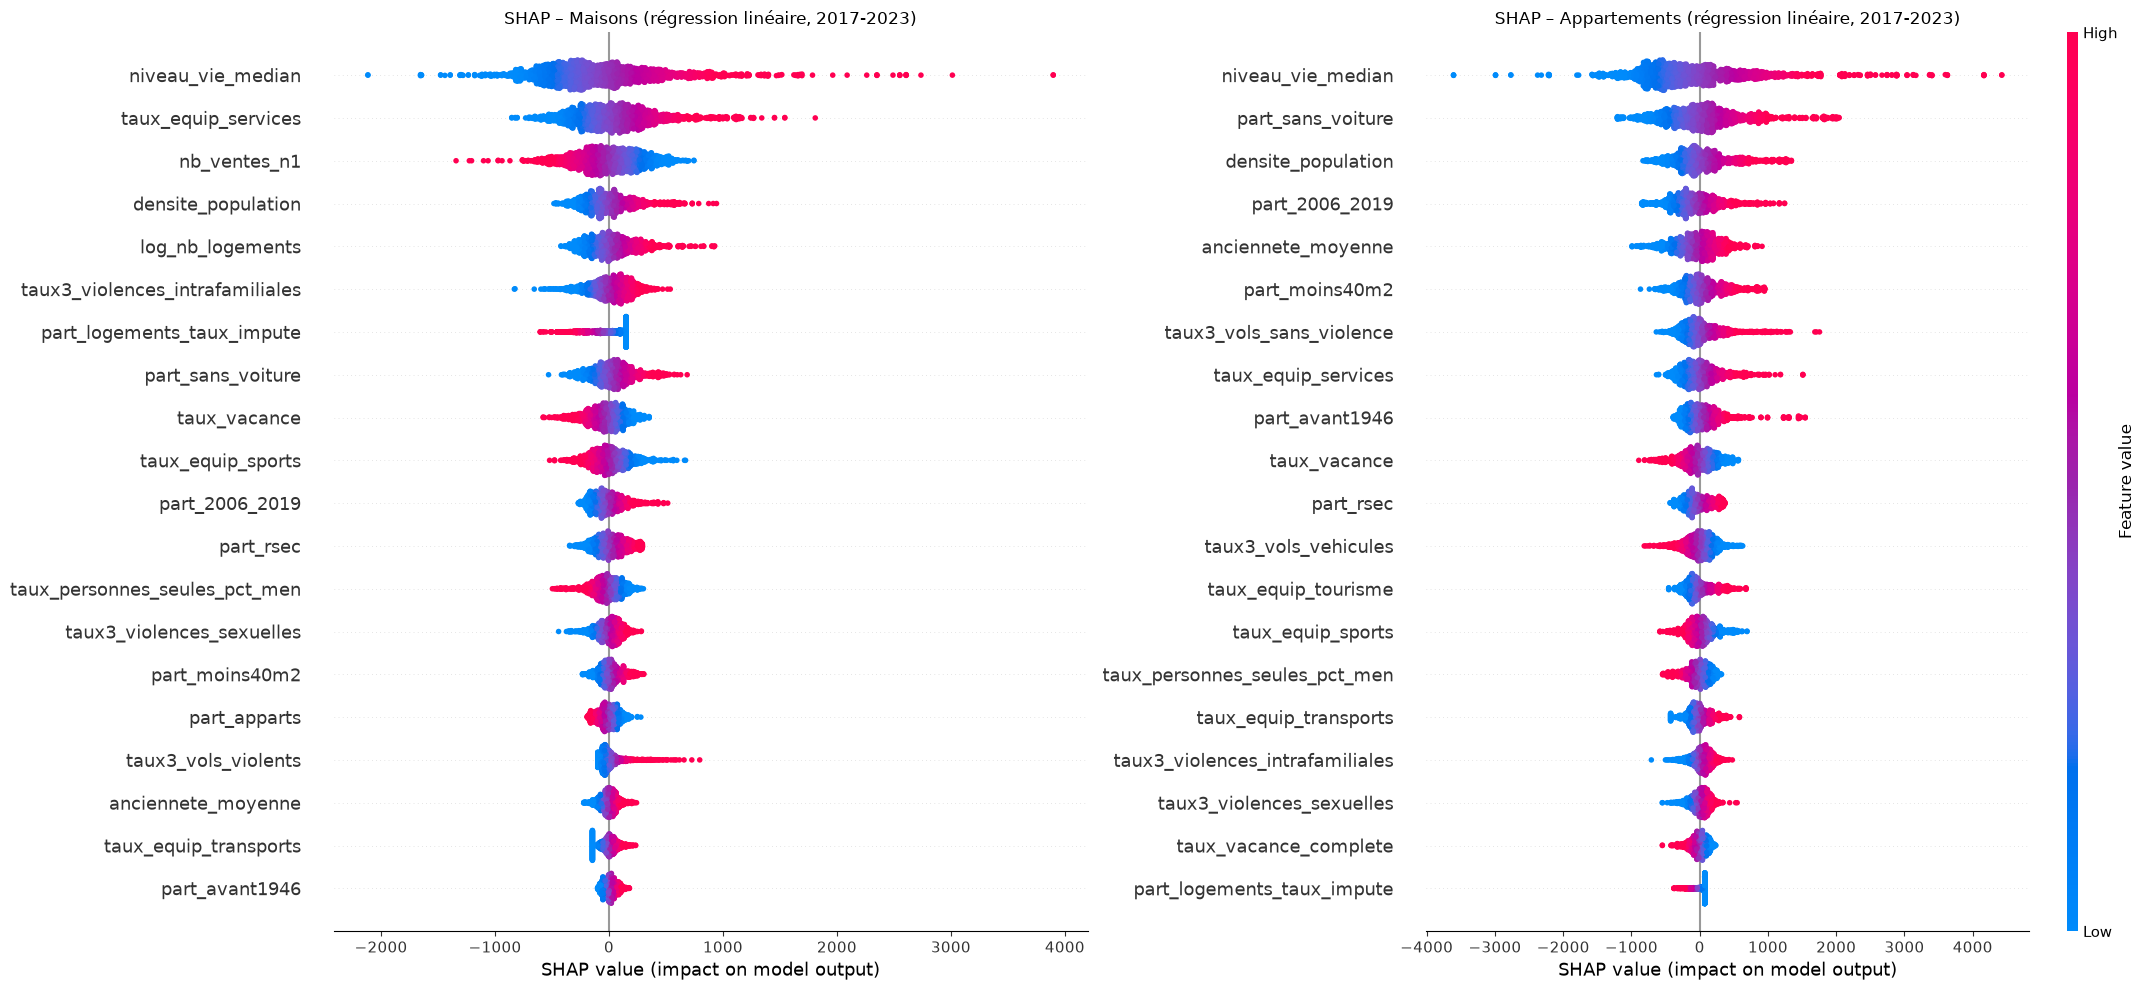

In [11]:
plt.figure(figsize=(22, 10))
for i, (nom, valeur) in enumerate([("Maisons", 1), ("Appartements", 0)], start=1):
    app_type = apprentissage[apprentissage["maison"] == valeur]
    X_t, y_t = app_type[variables_type], app_type[CIBLE]
    modele_t = LinearRegression().fit(X_t, y_t)

    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    valeurs_t = shap.LinearExplainer(modele_t, X_t).shap_values(echantillon_t)
    print(nom, ":", len(X_t), "lignes d'apprentissage")

    # Chaque graphique se dessine dans sa moitié de la figure
    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs_t, echantillon_t, max_display=20, show=False,
                      plot_size=None, color_bar=(i == 2))
    plt.title(f"SHAP – {nom} (régression linéaire, 2017-2023)")

plt.tight_layout()
plt.show()

**Comment lire les graphiques SHAP**
- Chaque point est un sous-bassin × année. Sa position dit de combien la variable fait monter (à droite) ou baisser (à gauche) le prix prévu, en €/m², par rapport au prix moyen. Sa couleur donne la valeur de la variable : rouge = élevée, bleu = faible.
- Les variables sont classées de la plus utilisée à la moins utilisée.
- **Deux variables liées en tête avec des effets opposés** (l'une à droite quand elle est rouge, l'autre à gauche) : signe d'une redondance ; le modèle se sert de leur petite différence. Leurs effets ne sont pas à interpréter séparément.
- **Ce n'est pas une cause** : une variable signale souvent un type de territoire.
- **Une variable de contrôle qualité utilisée par le modèle** mesure aussi le territoire ; elle reste hors des modèles.

### 8.3 Effet du retrait des variables redondantes
À compléter à chaque passage où la section 4 trouve des couples redondants : `REDONDANTES_A_TESTER` reçoit la variable proposée au retrait dans chaque couple. On compare alors deux régressions linéaires par type de bien, avec et sans ces variables, entraînées sur 2017-2023 et mesurées sur 2024 (année de validation).
- **R²** : part des écarts de prix entre sous-bassins que le modèle explique (1 = tout, 0 = rien) ;
- **MAE** : erreur moyenne en €/m², en valeur absolue.

In [12]:
REDONDANTES_A_TESTER = []          # variables proposées au retrait à ce passage (section 4)

JEUX = {"toutes les variables": variables_type}
if REDONDANTES_A_TESTER:
    JEUX["sans redondances"] = [c for c in variables_type if c not in REDONDANTES_A_TESTER]
JEU_RETENU = list(JEUX)[-1]        # jeu utilisé dans la suite de la section
print("Jeux comparés :", list(JEUX), "| jeu retenu pour la suite :", JEU_RETENU)

resultats, modeles = [], {}
for nom_jeu, vars_jeu in JEUX.items():
    for nom, valeur in [("Maisons", 1), ("Appartements", 0)]:
        app_t = apprentissage[apprentissage["maison"] == valeur]
        val_t = validation[validation["maison"] == valeur]
        modele_t = LinearRegression().fit(app_t[vars_jeu], app_t[CIBLE])
        modeles[(nom_jeu, nom)] = (modele_t, app_t[vars_jeu])
        resultats.append({
            "variables": nom_jeu, "type": nom, "nb variables": len(vars_jeu),
            "R² apprentissage": r2_score(app_t[CIBLE], modele_t.predict(app_t[vars_jeu])),
            "R² validation 2024": r2_score(val_t[CIBLE], modele_t.predict(val_t[vars_jeu])),
            "MAE validation 2024 (€/m²)": mean_absolute_error(val_t[CIBLE], modele_t.predict(val_t[vars_jeu])),
        })
display(pd.DataFrame(resultats).round(2))

Jeux comparés : ['toutes les variables'] | jeu retenu pour la suite : toutes les variables


,variables,type,nb variables,R² apprentissage,R² validation 2024,MAE validation 2024 (€/m²)
0,toutes les variables,Maisons,33,0.79,0.79,330.91
1,toutes les variables,Appartements,33,0.86,0.86,476.18


#### SHAP de la régression sans les variables redondantes

In [13]:
if "sans redondances" in JEUX:
    plt.figure(figsize=(22, 10))
    for i, nom in enumerate(["Maisons", "Appartements"], start=1):
        modele_t, X_t = modeles[("sans redondances", nom)]
        echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
        valeurs_t = shap.LinearExplainer(modele_t, X_t).shap_values(echantillon_t)

        plt.subplot(1, 2, i)
        shap.summary_plot(valeurs_t, echantillon_t, max_display=30, show=False,
                          plot_size=None, color_bar=(i == 2))
        plt.title(f"SHAP – {nom}, sans redondances (régression linéaire, 2017-2023)")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune variable redondante à tester à ce passage.")

Aucune variable redondante à tester à ce passage.


**Comment lire (exemple fictif : R² apprentissage 0,80, R² validation 0,74)**
- **R² validation** : part des écarts de prix de 2024, une année que le modèle n'a pas vue, qu'il explique.
- **R² apprentissage nettement plus haut que R² validation** : le modèle se généralise mal ; avec des variables redondantes, il peut s'appuyer sur leur petite différence, qui change d'une année à l'autre.
- **MAE** : si elle baisse sans les variables redondantes, leur retrait est confirmé.
- **SHAP sans redondances** : les effets opposés doivent disparaître, et le sens de chaque variable redevient lisible.

### 8.4 Comparaison avec une forêt aléatoire
Forêt aléatoire (200 arbres, profondeur 10, au moins 20 lignes par feuille) par type de bien, mêmes variables que le jeu retenu, entraînée sur 2017-2023, mesurée sur 2024. Le log ne change rien pour la forêt (mêmes coupures) : il est gardé pour comparer avec la régression sur la même table.

In [14]:
vars_rf = JEUX[JEU_RETENU]
resultats_rf, modeles_rf = [], {}
for nom, valeur in [("Maisons", 1), ("Appartements", 0)]:
    app_t = apprentissage[apprentissage["maison"] == valeur]
    val_t = validation[validation["maison"] == valeur]
    foret = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=20,
                                  n_jobs=-1, random_state=42).fit(app_t[vars_rf], app_t[CIBLE])
    modeles_rf[nom] = (foret, app_t[vars_rf])
    resultats_rf.append({
        "modèle": "forêt aléatoire", "type": nom,
        "R² apprentissage": r2_score(app_t[CIBLE], foret.predict(app_t[vars_rf])),
        "R² validation 2024": r2_score(val_t[CIBLE], foret.predict(val_t[vars_rf])),
        "MAE validation 2024 (€/m²)": mean_absolute_error(val_t[CIBLE], foret.predict(val_t[vars_rf])),
    })

# Comparaison avec la régression linéaire sur le même jeu de variables
lineaire = (pd.DataFrame(resultats).query("variables == @JEU_RETENU")
            .drop(columns=["variables", "nb variables"]).assign(**{"modèle": "régression linéaire"}))
display(pd.concat([lineaire, pd.DataFrame(resultats_rf)])
        .sort_values(["type", "modèle"]).round(2).reset_index(drop=True))

,type,R² apprentissage,R² validation 2024,MAE validation 2024 (€/m²),modèle
0,Appartements,0.94,0.91,353.18,forêt aléatoire
1,Appartements,0.86,0.86,476.18,régression linéaire
2,Maisons,0.87,0.88,219.68,forêt aléatoire
3,Maisons,0.79,0.79,330.91,régression linéaire


#### SHAP de la forêt aléatoire

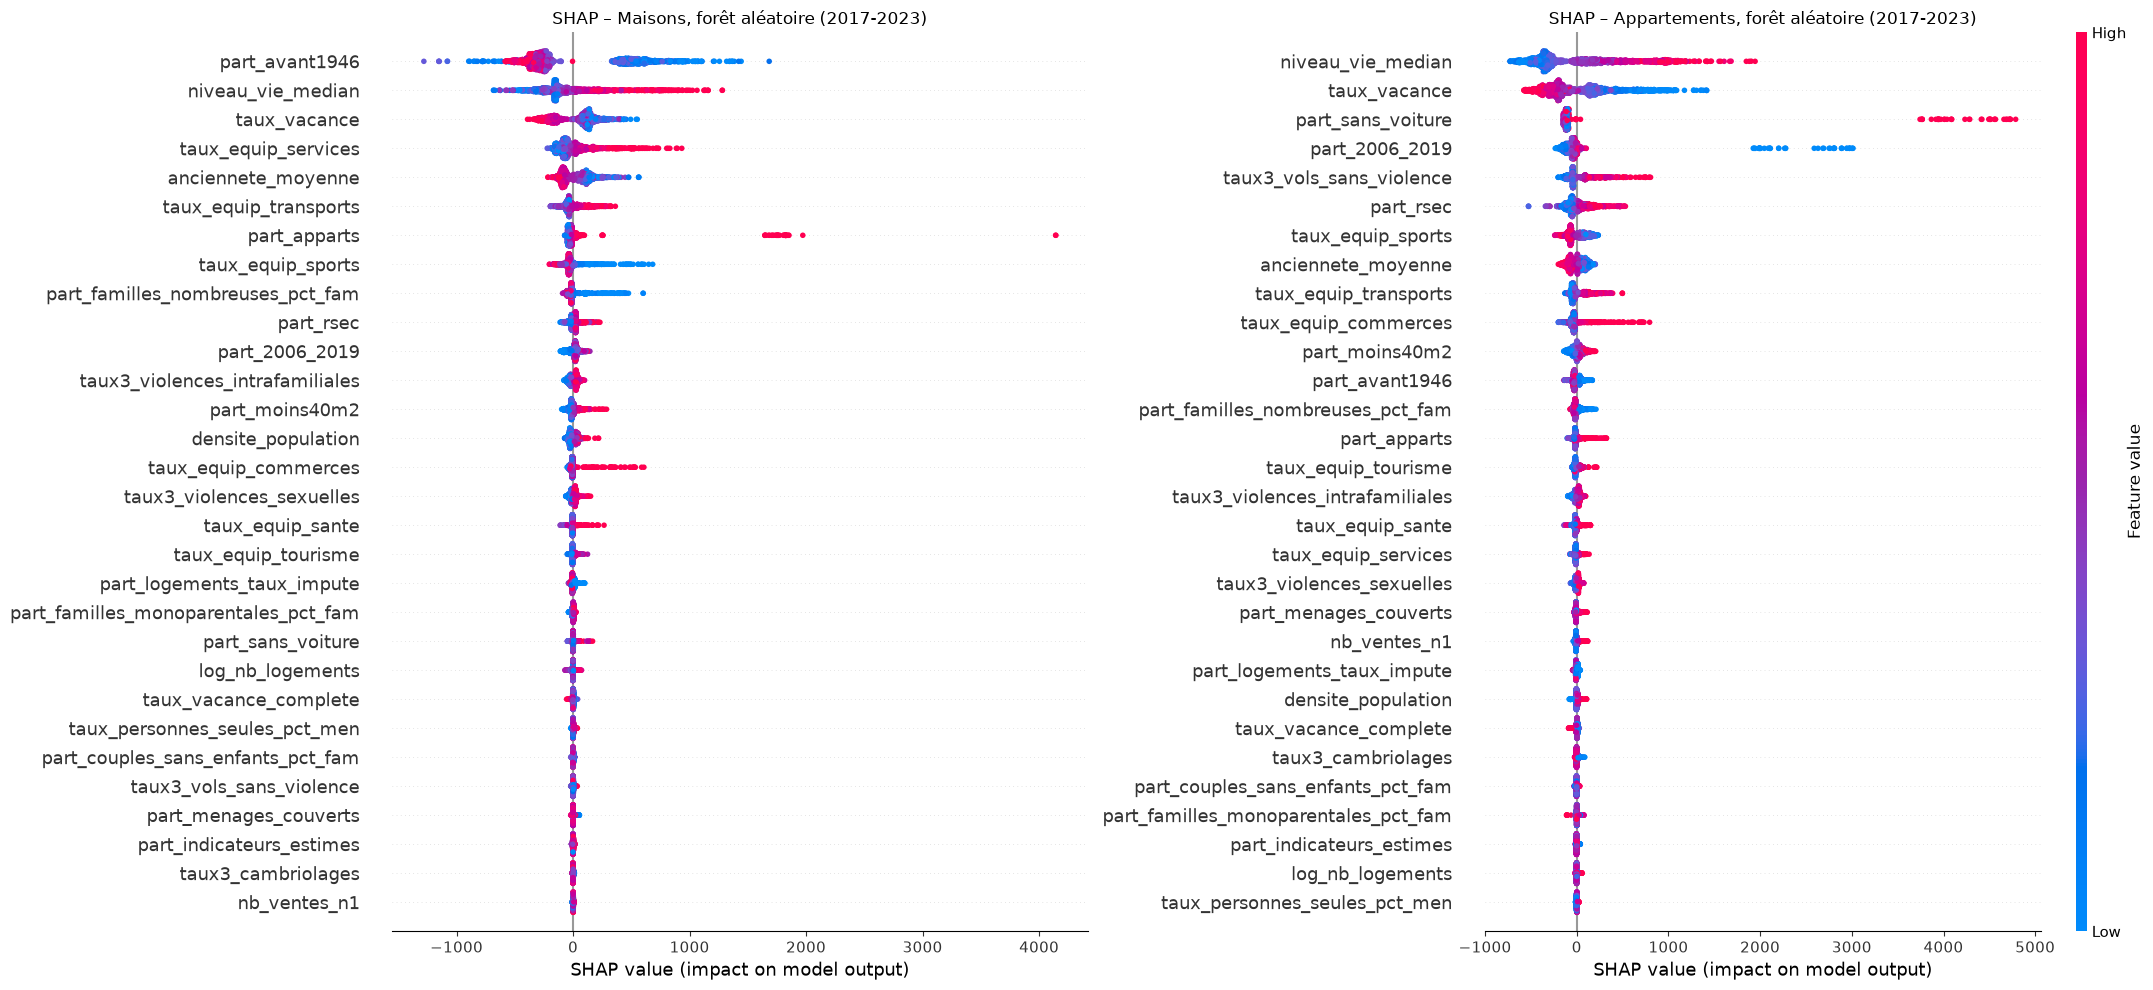

In [15]:
plt.figure(figsize=(22, 10))
for i, nom in enumerate(["Maisons", "Appartements"], start=1):
    foret, X_t = modeles_rf[nom]
    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    valeurs_t = shap.TreeExplainer(foret).shap_values(echantillon_t)

    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs_t, echantillon_t, max_display=30, show=False,
                      plot_size=None, color_bar=(i == 2))
    plt.title(f"SHAP – {nom}, forêt aléatoire (2017-2023)")

plt.tight_layout()
plt.show()

**Comment lire**
- **Forêt meilleure que la régression** (R² plus haut, MAE plus basse en validation) : une partie des liens avec le prix n'est pas en ligne droite (effets de seuil) ou dépend des autres variables (interactions).
- **Écart entre R² d'apprentissage et de validation** : faible, pas de surapprentissage marqué.
- **SHAP de la forêt** : des couleurs mélangées le long d'une ligne signalent des interactions ; un petit paquet de points très à droite signale un groupe de territoires à part (par exemple les arrondissements de Paris), reconnu par le modèle grâce à cette variable, et non un effet général de la variable.
- **Les variables importantes dépendent du modèle** : la régression donne l'effet de chaque variable, les autres égales ; la forêt choisit une variable par groupe de variables liées. Ne conclure que sur ce qui ressort des deux.

## 9. Variables qui ne comptent dans aucun modèle


Pour chacun des 4 modèles de la section 8 (régression et forêt, maisons et appartements) : part de chaque variable dans l'importance totale, à partir des valeurs SHAP (moyenne en valeur absolue). On garde la part la plus élevée des quatre : une variable sous 2 % dans tous les modèles ne compte nulle part.

In [16]:
# Part de chaque variable dans l'importance SHAP totale de chaque modèle (en %)
parts = {}
for nom in ["Maisons", "Appartements"]:
    modele_lin, X_t = modeles[(JEU_RETENU, nom)]
    foret, _ = modeles_rf[nom]
    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    for nom_modele, valeurs in [
        ("régression", shap.LinearExplainer(modele_lin, X_t).shap_values(echantillon_t)),
        ("forêt", shap.TreeExplainer(foret).shap_values(echantillon_t)),
    ]:
        imp = pd.Series(np.abs(valeurs).mean(axis=0), index=X_t.columns)
        parts[f"{nom} – {nom_modele}"] = imp / imp.sum() * 100

parts = pd.DataFrame(parts)
parts["part max (%)"] = parts.max(axis=1)
parts["compte nulle part (< 2 %)"] = parts["part max (%)"] < 2
print("Repère : avec", len(parts), "variables, une variable moyenne pèse", round(100 / len(parts), 1), "%")
display(parts.sort_values("part max (%)").round(1))

Background dataset has 12453 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=12453 when initializing the masker.
Background dataset has 5833 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5833 when initializing the masker.


Repère : avec 33 variables, une variable moyenne pèse 3.0 %


,Maisons – régression,Maisons – forêt,Appartements – régression,Appartements – forêt,part max (%),compte nulle part (< 2 %)
taux3_stupefiants,0.2,0.1,0.5,0.1,0.5,True
part_indicateurs_estimes,0.8,0.1,0.2,0.2,0.8,True
part_familles_monoparentales_pct_fam,1.0,0.4,0.8,0.2,1.0,True
part_menages_couverts,1.1,0.1,0.7,0.7,1.1,True
taux3_cambriolages,0.9,0.1,1.1,0.3,1.1,True
part_couples_sans_enfants_pct_fam,1.2,0.2,1.1,0.2,1.2,True
taux_equip_sante,1.4,0.8,0.5,1.0,1.4,True
taux_vacance_complete,0.4,0.2,1.9,0.4,1.9,True
taux3_vols_violents,2.2,0.1,0.7,0.1,2.2,False
part_familles_nombreuses_pct_fam,1.0,2.7,1.1,1.4,2.7,False


**Comment lire (exemple fictif : une variable à 1,1 % au plus)**
- **Part max** : dans le modèle où elle compte le plus, la variable pèse 1,1 % de l'importance totale. Sous 2 % partout, elle ne compte dans aucun modèle : candidate au retrait, à confirmer à la modélisation (erreur avec et sans).
- **Une variable forte dans un seul type de modèle** (par exemple 25 % dans la forêt et 1 % dans la régression) est à garder : elle agit par un effet de seuil ou une interaction.
- **Variables de contrôle qualité** : leur part dit seulement si elles mesurent aussi le territoire ; elles restent hors des modèles dans tous les cas.

## 10. Densité de population



`densite_population` est une photo fixe : une seule valeur par sous-bassin, identique pour toutes les années et pour les deux types de bien (habitants 2024 / superficie). Sa distribution s'étudie donc à la maille sous-bassin, sans compter chaque sous-bassin plusieurs fois. On regarde ensuite la place des 45 arrondissements de Paris, Lyon et Marseille, qui ont chacun leur superficie réelle.

Sous-bassins : 1811
Asymétrie brute      : 8.35
Asymétrie après log10 : 1.47


,densite_population
count,1811.0
mean,562.0
std,2822.0
min,6.0
25%,40.0
50%,75.0
75%,161.0
max,37873.0


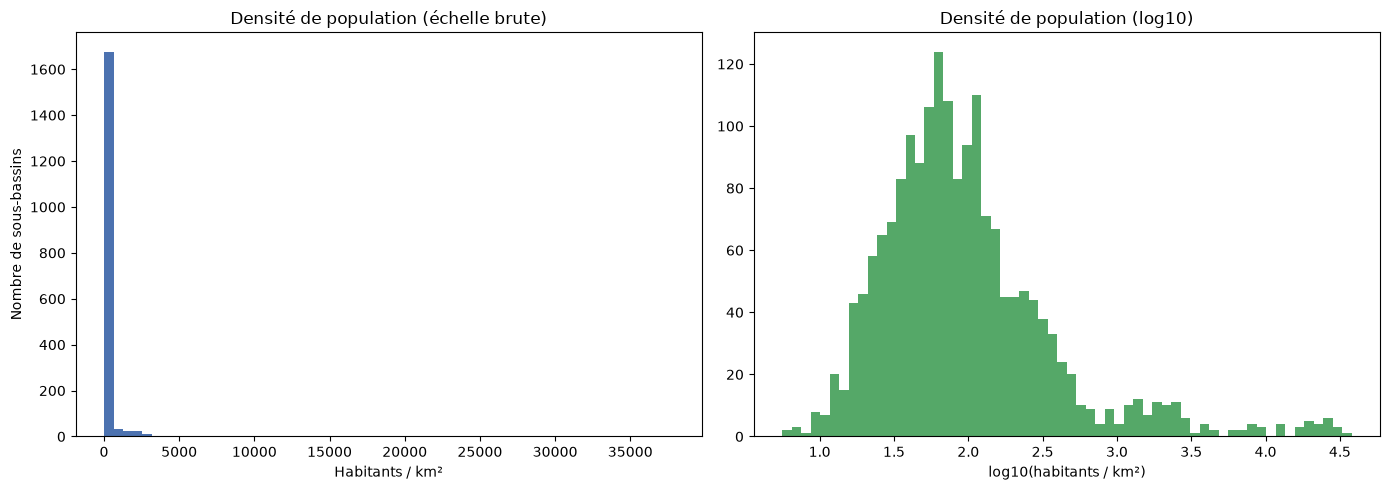

In [17]:
# Contrôle : une seule valeur de densité par sous-bassin
assert (plat.groupby("sous_bassin_de_vie")["densite_population"].nunique() <= 1).all()

dens = plat.drop_duplicates("sous_bassin_de_vie").set_index("sous_bassin_de_vie")["densite_population"]

print("Sous-bassins :", len(dens))
print("Asymétrie brute      :", round(dens.skew(), 2))
print("Asymétrie après log10 :", round(np.log10(dens).skew(), 2))
display(dens.describe().round(0).to_frame("densite_population"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(dens, bins=60, color="#4C72B0")
axes[0].set_title("Densité de population (échelle brute)")
axes[0].set_xlabel("Habitants / km²")
axes[0].set_ylabel("Nombre de sous-bassins")
axes[1].hist(np.log10(dens), bins=60, color="#55A868")
axes[1].set_title("Densité de population (log10)")
axes[1].set_xlabel("log10(habitants / km²)")
plt.tight_layout()
plt.show()

### Les arrondissements de Paris, Lyon et Marseille

,arrondissements,densite_min,densite_mediane,densite_max,densites_distinctes
ville,,,,,
Lyon,9,7106.0,11938.0,18603.0,9
Marseille,16,1119.0,5185.0,22818.0,16
Paris,20,8271.0,24868.0,37873.0,20


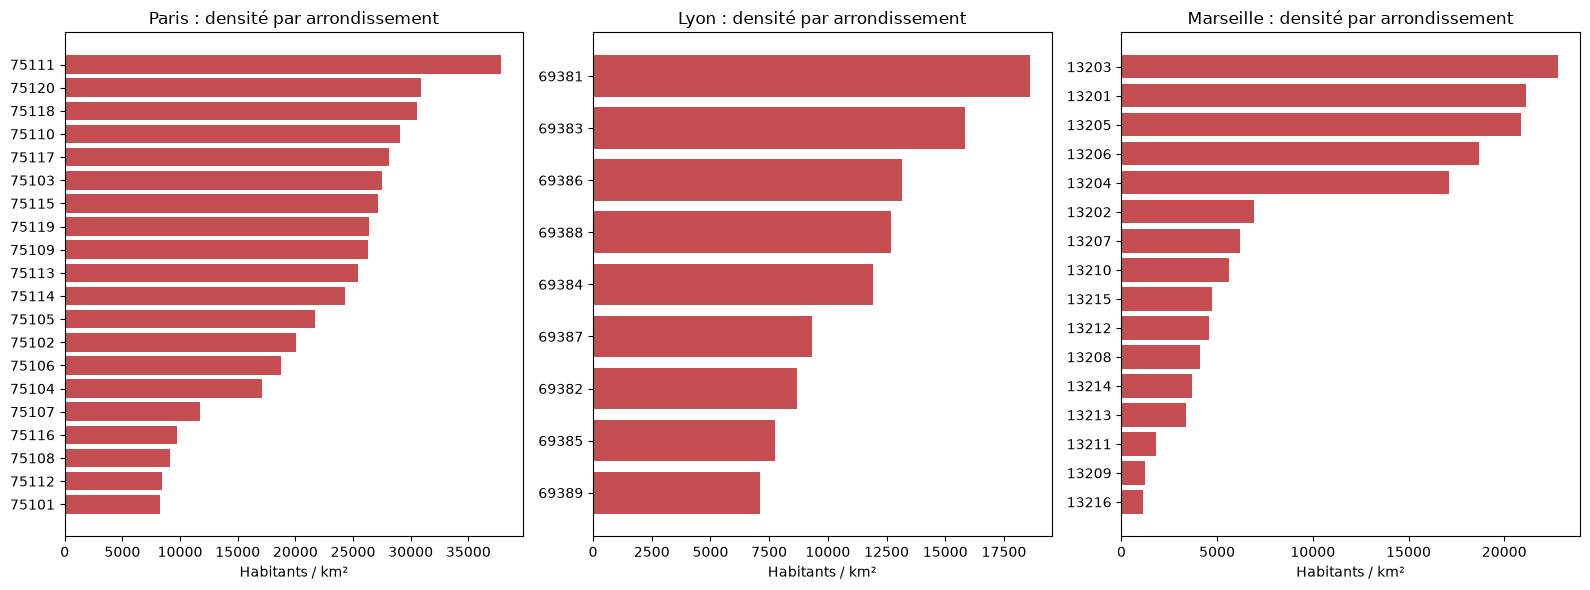

,sous-bassins au-dessus du seuil,dont arrondissements
> 1000 hab/km²,112,45
> 5000 hab/km²,37,37
> 10000 hab/km²,26,26


Densité maximale hors arrondissements : 3889 (sous-bassin 56121_1)


In [18]:
motifs = {"Paris": r"^751\d\d$", "Lyon": r"^6938\d$", "Marseille": r"^132\d\d$"}

lignes = []
for ville, motif in motifs.items():
    dv = dens[dens.index.str.match(motif)]
    for code_arr, valeur in dv.items():
        lignes.append({"ville": ville, "arrondissement": code_arr, "densite": valeur})
arr = pd.DataFrame(lignes)

resume = (arr.groupby("ville")["densite"]
          .agg(arrondissements="count", densite_min="min", densite_mediane="median", densite_max="max",
               densites_distinctes=lambda s: s.round(0).nunique())
          .round(0))
display(resume)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, ville in zip(axes, ["Paris", "Lyon", "Marseille"]):
    dv = arr[arr["ville"] == ville].sort_values("densite")
    ax.barh(dv["arrondissement"], dv["densite"], color="#C44E52")
    ax.set_title(f"{ville} : densité par arrondissement")
    ax.set_xlabel("Habitants / km²")
plt.tight_layout()
plt.show()

# Place des arrondissements dans la distribution
seuils = [1000, 5000, 10000]
est_arr = dens.index.isin(arr["arrondissement"])
display(pd.DataFrame({
    "sous-bassins au-dessus du seuil": [(dens > s).sum() for s in seuils],
    "dont arrondissements":            [((dens > s) & est_arr).sum() for s in seuils],
}, index=[f"> {s} hab/km²" for s in seuils]))
print("Densité maximale hors arrondissements :", round(dens[~est_arr].max()),
      "(sous-bassin", dens[~est_arr].idxmax() + ")")

### Densité et prix

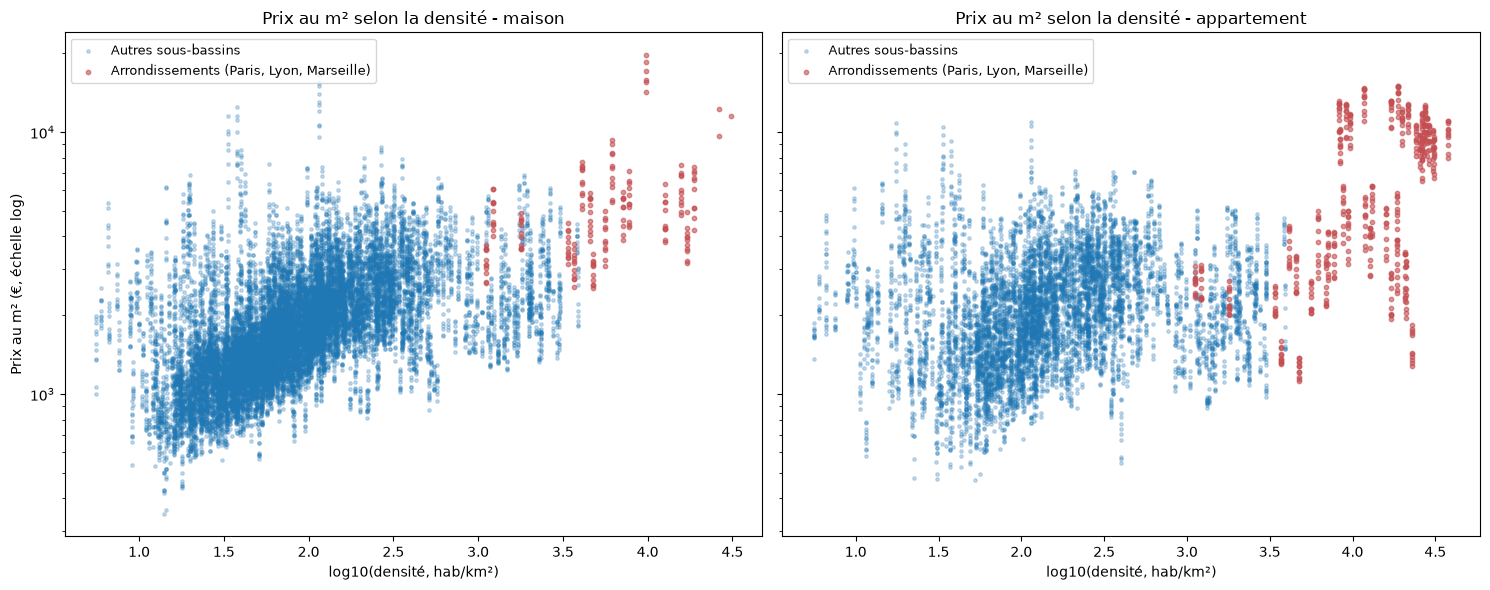

Corrélation de Spearman densité / prix :
  maison       0.62
  appartement  0.36


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, type_bien in zip(axes, ["maison", "appartement"]):
    sous = plat[plat["type_bien"] == type_bien].dropna(subset=[CIBLE])
    est_arr_ligne = sous["sous_bassin_de_vie"].isin(arr["arrondissement"])
    ax.scatter(np.log10(sous.loc[~est_arr_ligne, "densite_population"]),
               sous.loc[~est_arr_ligne, CIBLE], s=6, alpha=0.25, label="Autres sous-bassins")
    ax.scatter(np.log10(sous.loc[est_arr_ligne, "densite_population"]),
               sous.loc[est_arr_ligne, CIBLE], s=10, alpha=0.6, color="#C44E52",
               label="Arrondissements (Paris, Lyon, Marseille)")
    ax.set_yscale("log")
    ax.set_title(f"Prix au m² selon la densité - {type_bien}")
    ax.set_xlabel("log10(densité, hab/km²)")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Prix au m² (€, échelle log)")
plt.tight_layout()
plt.show()

print("Corrélation de Spearman densité / prix :")
for type_bien in ["maison", "appartement"]:
    sous = plat[plat["type_bien"] == type_bien]
    print(f"  {type_bien:12s}", round(sous[["densite_population", CIBLE]].corr(method="spearman").iloc[0, 1], 2))

**Comment lire**
- **Asymétrie avant et après log10** : une forte baisse justifie le log de la densité pour les modèles linéaires.
- **Arrondissements** : chacun doit avoir sa propre densité (autant de densités distinctes que d'arrondissements). Si tous les sous-bassins au-dessus d'un seuil sont des arrondissements, ceux-ci forment un groupe à part, qui peut tirer un modèle linéaire non transformé : une analyse de sensibilité avec et sans arrondissements est alors utile.
- **Densité et prix** : un ρ positif plus fort pour un type de bien que pour l'autre indique que l'effet de la densité dépend du marché.

## 11. ACP



**Pourquoi :** les variables du territoire sont liées entre elles. L'ACP cherche les quelques grandes différences entre territoires qu'elles décrivent, puis on regarde si ces axes suffisent à prévoir le prix.

**Choix :** une ligne par sous-bassin et par année d'apprentissage (2020-2023) ; variables du territoire passées en log selon la règle de la section 3, puis standardisées (moyenne 0, écart-type 1) pour qu'aucune ne pèse plus à cause de son unité. Le prix n'entre pas dans l'ACP.

### 11.1 Nombre d'axes

7236 lignes, 29 variables
Part de l'information par axe (%) : [29.9 19.9 12.6  5.1  4.6  3.6]
Part cumulée (%) : [29.9 49.8 62.5 67.6 72.2 75.8]


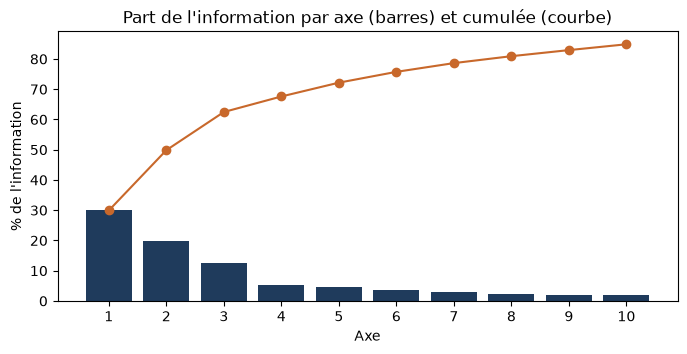

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Une ligne par sous-bassin x année : les variables du territoire ne dépendent pas du type de bien
territoires = apprentissage_plat.drop_duplicates(["annee", "sous_bassin_de_vie"])
donnees_acp = territoires.dropna(subset=TERRITOIRE)
normalisation = StandardScaler().fit(passer_en_log(donnees_acp[TERRITOIRE]))   # moyennes et écarts-types de 2020-2023
Z = normalisation.transform(passer_en_log(donnees_acp[TERRITOIRE]))
acp_simple = PCA().fit(Z)
part = acp_simple.explained_variance_ratio_ * 100
print(len(donnees_acp), "lignes,", len(TERRITOIRE), "variables")
print("Part de l'information par axe (%) :", np.round(part[:6], 1))
print("Part cumulée (%) :", np.round(np.cumsum(part[:6]), 1))

plt.figure(figsize=(8, 3.5))
plt.bar(range(1, 11), part[:10], color="#1f3b5c")
plt.plot(range(1, 11), np.cumsum(part[:10]), color="#c8682b", marker="o")
plt.xlabel("Axe")
plt.ylabel("% de l'information")
plt.xticks(range(1, 11))
plt.title("Part de l'information par axe (barres) et cumulée (courbe)")
plt.show()

**Comment lire**
- On retient les premiers axes, jusqu'au « coude » : là où chaque axe supplémentaire n'apporte plus que quelques pourcents. La suite de la section interprète les 3 premiers axes.
- **Part cumulée** : part de l'information des variables conservée par ces axes ; le reste est perdu si l'on ne garde que les axes.

### 11.2 Ce que mesurent les axes
La corrélation de chaque variable avec un axe montre ce qu'il mesure. Le cercle des corrélations le représente pour les deux premiers axes : chaque flèche est une variable, et deux flèches proches vont ensemble.

F1 | négatif : {'anciennete_moyenne': -0.65, 'taux_equip_sports': -0.56, 'part_2006_2019': -0.17, 'part_couples_sans_enfants_pct_fam': -0.13} | positif : {'taux3_vols_violents': 0.81, 'part_apparts': 0.81, 'taux3_vols_sans_violence': 0.88, 'part_moins40m2': 0.9}
F2 | négatif : {'densite_population': -0.59, 'part_2006_2019': -0.58, 'part_familles_nombreuses_pct_fam': -0.53, 'niveau_vie_median': -0.5} | positif : {'part_avant1946': 0.63, 'taux_vacance_complete': 0.72, 'part_rsec': 0.72, 'part_couples_sans_enfants_pct_fam': 0.76}
F3 | négatif : {'part_2006_2019': -0.55, 'taux_equip_tourisme': -0.55, 'taux_equip_services': -0.54, 'part_rsec': -0.49} | positif : {'part_avant1946': 0.44, 'taux_vacance': 0.56, 'taux3_violences_intrafamiliales': 0.58, 'part_familles_nombreuses_pct_fam': 0.61}


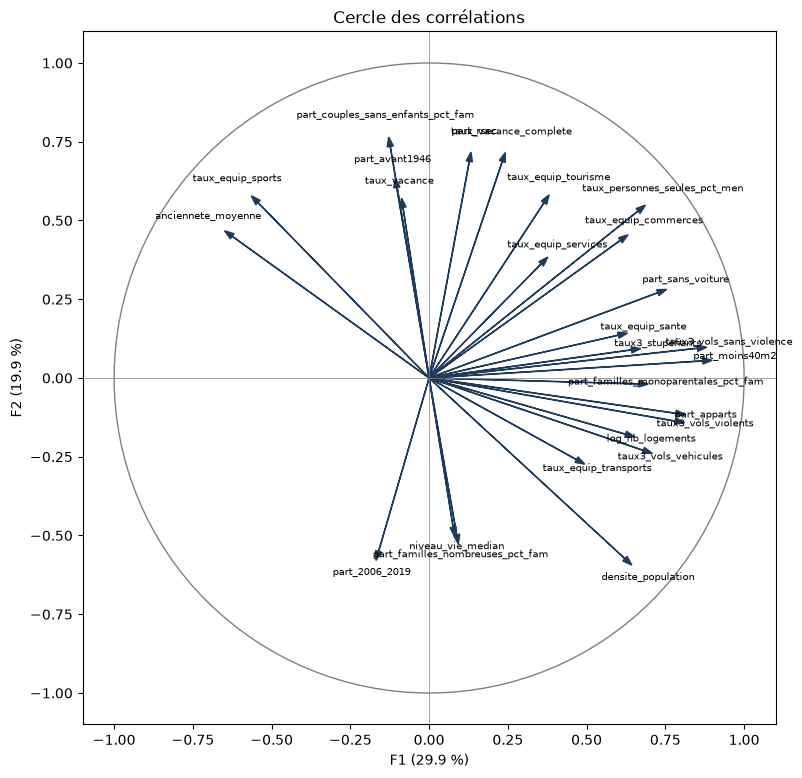

In [21]:
# Corrélation de chaque variable avec les 3 premiers axes
correlations = pd.DataFrame(acp_simple.components_[:3].T * np.sqrt(acp_simple.explained_variance_[:3]),
                            index=TERRITOIRE, columns=["F1", "F2", "F3"])
for f in ["F1", "F2", "F3"]:
    s = correlations[f].sort_values()
    print(f, "| négatif :", s.head(4).round(2).to_dict(), "| positif :", s.tail(4).round(2).to_dict())

# Cercle des corrélations (F1, F2) : seules les variables bien représentées sont tracées
fig, ax = plt.subplots(figsize=(9, 9))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for v in TERRITOIRE:
    x = correlations.loc[v, "F1"]
    y = correlations.loc[v, "F2"]
    if x ** 2 + y ** 2 > 0.25:
        ax.arrow(0, 0, x, y, head_width=0.02, color="#1f3b5c", length_includes_head=True)
        ax.text(x * 1.08, y * 1.08, v, fontsize=7, ha="center")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.set_xlabel("F1 (" + str(round(part[0], 1)) + " %)")
ax.set_ylabel("F2 (" + str(round(part[1], 1)) + " %)")
ax.set_title("Cercle des corrélations")
plt.show()

**Comment lire**
- Pour nommer un axe, on regarde les variables les plus corrélées avec lui, à chaque extrémité : l'axe oppose les territoires où les premières sont élevées à ceux où ce sont les secondes.
- **Cercle** : une flèche proche du cercle est bien représentée par les deux axes ; deux flèches dans le même sens vont ensemble, deux flèches opposées varient en sens contraire.
- Le signe d'un axe est arbitraire : un axe peut être inversé d'un passage à l'autre sans que sa lecture change.

### 11.3 Lien entre les axes et le prix

In [22]:
# Coordonnées de chaque sous-bassin x année sur les 3 axes, rapprochées du prix
axes_acp = pd.DataFrame(acp_simple.transform(Z)[:, :3], columns=["F1", "F2", "F3"], index=donnees_acp.index)
axes_acp[["annee", "sous_bassin_de_vie"]] = donnees_acp[["annee", "sous_bassin_de_vie"]]
for type_bien in ["maison", "appartement"]:
    a = apprentissage_plat[apprentissage_plat["type_bien"] == type_bien].merge(axes_acp, on=["annee", "sous_bassin_de_vie"])
    print(type_bien, ": F1 =", round(stats.spearmanr(a["F1"], a[CIBLE])[0], 2),
          "| F2 =", round(stats.spearmanr(a["F2"], a[CIBLE])[0], 2),
          "| F3 =", round(stats.spearmanr(a["F3"], a[CIBLE])[0], 2))

maison : F1 = 0.42 | F2 = -0.58 | F3 = -0.55
appartement : F1 = 0.3 | F2 = -0.25 | F3 = -0.52


**Comment lire** : mêmes repères que la section 6 (0,1 faible, 0,3 moyen, 0,5 fort). L'axe le plus lié au prix dit quelle grande différence entre territoires compte le plus pour chaque type de bien.

### 11.4 Les axes suffisent-ils à prévoir le prix ?
Une forêt aléatoire par type de bien, entraînée deux fois sur 2020-2023 : sur les 3 axes, puis sur toutes les variables du territoire. Validation sur 2024 : les notes 2024 sont calculées avec la standardisation et l'ACP apprises sur 2020-2023. Sans le prix N-1 : on mesure ce que le territoire explique seul.

In [23]:
validation_plat = plat[plat["annee"] == ANNEE_VALIDATION]


def notes_acp(donnees):
    """Notes F1, F2, F3 des lignes, avec la standardisation et l'ACP apprises sur 2020-2023."""
    Z_lignes = normalisation.transform(passer_en_log(donnees[TERRITOIRE]))
    return pd.DataFrame(acp_simple.transform(Z_lignes)[:, :3], columns=["F1", "F2", "F3"], index=donnees.index)


JEUX_ACP = {"3 axes de l'ACP": ["F1", "F2", "F3"], f"{len(TERRITOIRE)} variables": TERRITOIRE}
resultats_acp, modeles_acp = [], {}

for type_bien in ["maison", "appartement"]:
    # Lignes du type de bien, avec leurs notes sur les 3 axes ajoutées en colonnes
    app = apprentissage_plat[apprentissage_plat["type_bien"] == type_bien].dropna(subset=TERRITOIRE)
    val = validation_plat[validation_plat["type_bien"] == type_bien].dropna(subset=TERRITOIRE)
    app = pd.concat([app, notes_acp(app)], axis=1)
    val = pd.concat([val, notes_acp(val)], axis=1)

    for nom_jeu, colonnes in JEUX_ACP.items():
        foret = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
        foret.fit(app[colonnes], app[CIBLE])
        prevision = foret.predict(val[colonnes])
        modeles_acp[(type_bien, nom_jeu)] = (foret, app[colonnes])
        resultats_acp.append({"type de bien": type_bien, "variables": nom_jeu,
                              "R² validation 2024": r2_score(val[CIBLE], prevision),
                              "MAE 2024 (€/m²)": mean_absolute_error(val[CIBLE], prevision),
                              "MAE naïve (€/m²)": mean_absolute_error(val[CIBLE], val["prix_n1"])})

display(pd.DataFrame(resultats_acp).round(2))

,type de bien,variables,R² validation 2024,MAE 2024 (€/m²),MAE naïve (€/m²)
0,maison,3 axes de l'ACP,0.74,333.83,129.19
1,maison,29 variables,0.89,187.23,129.19
2,appartement,3 axes de l'ACP,0.76,551.65,148.00
3,appartement,29 variables,0.91,308.28,148.00


**Comment lire**
- **R² des 3 axes** : part des écarts de prix entre territoires expliquée avec seulement 3 nombres par sous-bassin.
- **MAE des axes comparée à celle de toutes les variables** : si elle est nettement plus forte, l'information laissée de côté par l'ACP compte pour le prix ; on garde alors les variables d'origine dans les modèles, et les axes servent à expliquer les résultats.
- **MAE naïve** (prix N = prix N-1) : rappel de la référence à battre ; sans le prix N-1, un modèle du territoire seul ne l'approche pas, car le territoire dit où les prix sont hauts, pas comment ils évoluent.

### 11.5 Comment la forêt se sert des axes (SHAP)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
 93%|=================== | 931/1000 [00:11<00:00]       Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


maison : {'F1': 31.0, 'F2': 35.0, 'F3': 35.0}
appartement : {'F1': 36.0, 'F2': 22.0, 'F3': 42.0}


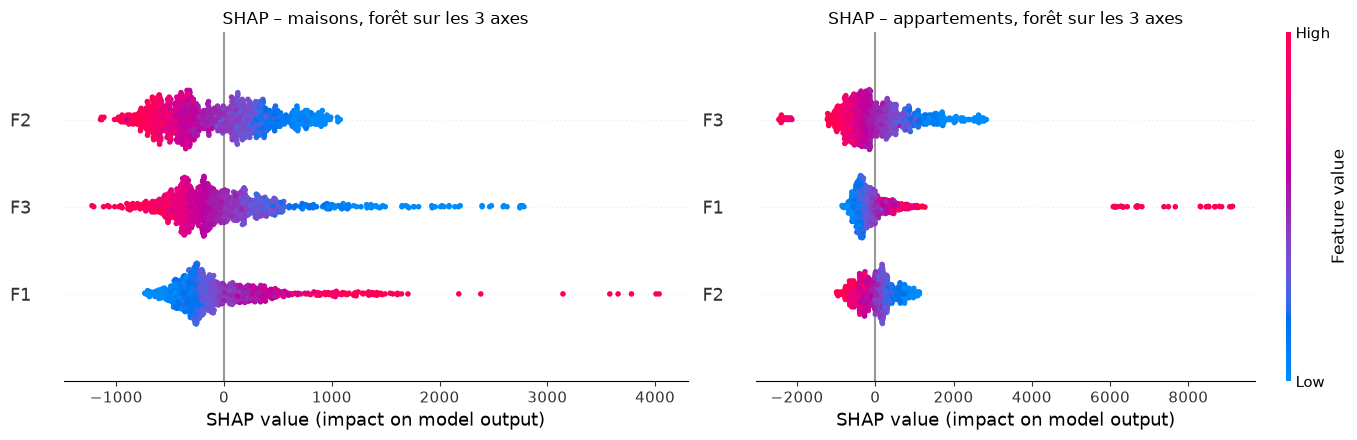

In [24]:
plt.figure(figsize=(14, 4.5))
for i, type_bien in enumerate(["maison", "appartement"], start=1):
    foret, X = modeles_acp[(type_bien, "3 axes de l'ACP")]
    echantillon = X.sample(min(1000, len(X)), random_state=42)     # 1 000 lignes suffisent pour le graphique
    reference = X.sample(min(200, len(X)), random_state=1)        # lignes de référence pour le prix moyen
    valeurs = shap.TreeExplainer(foret, reference).shap_values(echantillon)

    # Part de chaque axe dans l'importance totale (moyenne des valeurs SHAP en valeur absolue)
    importance = pd.Series(np.abs(valeurs).mean(axis=0), index=X.columns)
    print(type_bien, ":", (importance / importance.sum() * 100).round(0).to_dict())

    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs, echantillon, show=False, plot_size=None, color_bar=(i == 2))
    plt.title("SHAP – " + type_bien + "s, forêt sur les 3 axes")

plt.tight_layout()
plt.show()

**Comment lire** : même lecture que les graphiques SHAP de la section 8. La part de chaque axe dit lequel la forêt utilise le plus ; un axe qui n'agit que par ses valeurs extrêmes (quelques points très à droite) traduit un effet de seuil, qu'un arbre capte et qu'une régression linéaire capterait mal.

## 12. ACP, Berklet&KMO


Quatre critères pour décider si une ACP est utile : le nombre d'observations par variable, la colinéarité (VIF), l'adéquation des données à une ACP (Bartlett, KMO), et surtout ce que l'ACP coûte ou rapporte en prédiction.

**Choix :** une ligne par sous-bassin, avec les variables du territoire qui ne changent pas d'une année à l'autre (photos fixes) ; variables passées en log selon la règle de la section 3, puis standardisées.

### 12.1 Variables fixes et colinéarité

In [25]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict

# Variables du territoire qui ont une seule valeur par sous-bassin sur toutes les années
une_valeur = plat.groupby("sous_bassin_de_vie")[TERRITOIRE].nunique(dropna=True).max()
STATIQUES = [c for c in TERRITOIRE if une_valeur[c] <= 1]
print(len(STATIQUES), "variables fixes :", STATIQUES)
print("Variables qui changent dans le temps :", [c for c in TERRITOIRE if c not in STATIQUES])

zones = plat.drop_duplicates("sous_bassin_de_vie").set_index("sous_bassin_de_vie")[STATIQUES]
zones = passer_en_log(zones)
print("Valeurs vides avant complétion :", zones.isna().sum()[lambda s: s > 0].to_dict())
zones = zones.fillna(zones.median())

Xz = StandardScaler().fit_transform(zones)
R = np.corrcoef(Xz, rowvar=False)
R_inv = np.linalg.pinv(R)
vif = pd.Series(np.diag(R_inv), index=STATIQUES).sort_values(ascending=False)   # VIF = diagonale de l'inverse de R

print(f"\n{len(zones)} sous-bassins × {len(STATIQUES)} variables → {len(zones) / len(STATIQUES):.0f} observations par variable")
print(f"Paires avec |r| > 0,8 : {int((np.abs(np.triu(R, 1)) > 0.8).sum())}")
print("\nVIF (> 10 = colinéarité forte) :")
print(vif.round(1).to_string())

18 variables fixes : ['taux_vacance_complete', 'taux_equip_commerces', 'taux_equip_sante', 'taux_equip_services', 'taux_equip_sports', 'taux_equip_tourisme', 'taux_equip_transports', 'densite_population', 'taux_vacance', 'part_rsec', 'part_apparts', 'log_nb_logements', 'part_moins40m2', 'part_avant1946', 'part_2006_2019', 'anciennete_moyenne', 'part_sans_voiture', 'niveau_vie_median']
Variables qui changent dans le temps : ['taux3_vols_vehicules', 'taux3_vols_violents', 'taux3_vols_sans_violence', 'taux3_cambriolages', 'taux3_stupefiants', 'taux3_violences_intrafamiliales', 'taux3_violences_sexuelles', 'taux_personnes_seules_pct_men', 'part_familles_monoparentales_pct_fam', 'part_familles_nombreuses_pct_fam', 'part_couples_sans_enfants_pct_fam']
Valeurs vides avant complétion : {'taux_vacance_complete': 1}

1811 sous-bassins × 18 variables → 101 observations par variable
Paires avec |r| > 0,8 : 1

VIF (> 10 = colinéarité forte) :
part_sans_voiture        8.6
densite_population       6.

**Comment lire**
- **Observations par variable** : au-delà de quelques dizaines, il n'y a pas de problème de dimension ; réduire le nombre de variables n'est alors pas nécessaire pour prédire.
- **VIF** : 1 = variable indépendante des autres ; au-delà de 10, elle est presque entièrement prévisible à partir des autres (colinéarité forte). La colinéarité rend les coefficients d'une régression linéaire instables et difficiles à lire, sans gêner la prédiction d'un modèle à arbres.

### 12.2 Les données se prêtent-elles à une ACP ? (Bartlett, KMO)

In [26]:
n, p = Xz.shape
logdet = np.linalg.slogdet(R)[1]
chi2_b = -(n - 1 - (2 * p + 5) / 6) * logdet
ddl_b = p * (p - 1) / 2

partielle = -R_inv / np.sqrt(np.outer(np.diag(R_inv), np.diag(R_inv)))
np.fill_diagonal(partielle, 0)
R0 = R.copy()
np.fill_diagonal(R0, 0)
kmo = (R0 ** 2).sum() / ((R0 ** 2).sum() + (partielle ** 2).sum())
msa = pd.Series((R0 ** 2).sum(0) / ((R0 ** 2).sum(0) + (partielle ** 2).sum(0)), index=STATIQUES)

print(f"Bartlett : chi² = {chi2_b:,.0f} pour {ddl_b:.0f} ddl, p = {stats.chi2.sf(chi2_b, ddl_b):.1e}")
print(f"KMO global : {kmo:.2f}")
print("MSA par variable, les 5 plus faibles :", msa.sort_values().head(5).round(2).to_dict())

Bartlett : chi² = 25,847 pour 153 ddl, p = 0.0e+00
KMO global : 0.82
MSA par variable, les 5 plus faibles : {'niveau_vie_median': 0.59, 'part_sans_voiture': 0.71, 'taux_equip_services': 0.72, 'part_avant1946': 0.74, 'part_2006_2019': 0.76}


**Comment lire**
- **Bartlett** : teste si les variables sont indépendantes ; une p-value très faible veut dire qu'elles partagent de l'information, donc qu'une ACP a du sens.
- **KMO** (de 0 à 1) : qualité globale du résumé possible ; repères de Kaiser : sous 0,5 inacceptable, 0,7 moyen, 0,8 à 0,9 très bon.
- **MSA par variable** : une valeur faible signale une variable presque indépendante des autres ; elle porte une information propre, que les premiers axes résumeront mal.

### 12.3 Nombre d'axes (Kaiser et analyse parallèle de Horn)

    valeur propre  seuil Horn (95 %)  % variance  % cumulé
F1           5.54               1.21       30.74     30.74
F2           4.34               1.16       24.10     54.84
F3           2.48               1.14       13.76     68.60
F4           0.97               1.12        5.37     73.97
F5           0.74               1.10        4.14     78.11
F6           0.65               1.07        3.64     81.74
F7           0.59               1.05        3.27     85.02
F8           0.51               1.03        2.85     87.87

Axes retenus : Kaiser = 3, Horn = 3 → K = 3


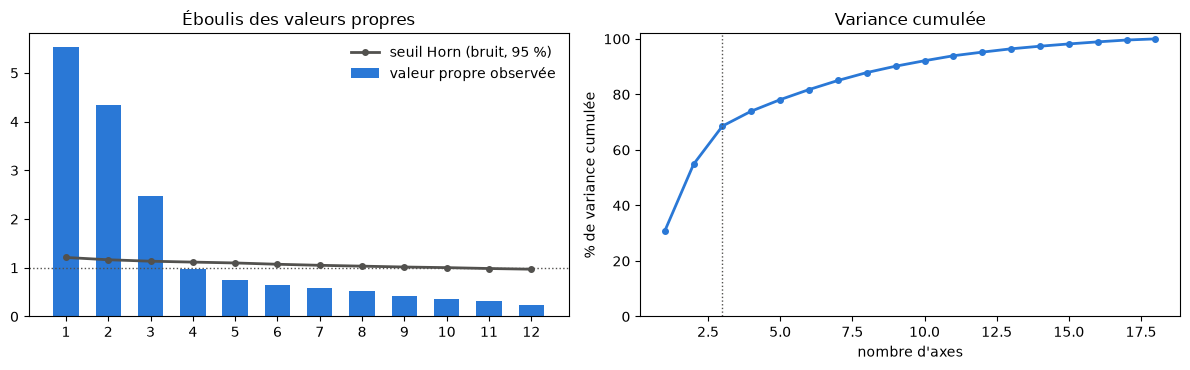

In [27]:
acp_complete = PCA().fit(Xz)
vp = acp_complete.explained_variance_

rng = np.random.default_rng(0)
vp_hasard = np.array([PCA().fit(StandardScaler().fit_transform(rng.standard_normal(Xz.shape))).explained_variance_
                      for _ in range(50)])
seuil_horn = np.percentile(vp_hasard, 95, axis=0)
k_kaiser, k_horn = int((vp > 1).sum()), int((vp > seuil_horn).sum())
K = max(k_horn, 2)                     # nombre d'axes retenu pour la suite : celui de Horn (au moins 2)
cum = acp_complete.explained_variance_ratio_.cumsum()

nb = min(8, p)
print(pd.DataFrame({"valeur propre": vp[:nb], "seuil Horn (95 %)": seuil_horn[:nb],
                    "% variance": acp_complete.explained_variance_ratio_[:nb] * 100, "% cumulé": cum[:nb] * 100},
                   index=[f"F{i+1}" for i in range(nb)]).round(2).to_string())
print(f"\nAxes retenus : Kaiser = {k_kaiser}, Horn = {k_horn} → K = {K}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(1, min(12, p) + 1)
ax[0].bar(x, vp[:len(x)], color="#2a78d6", width=0.6, label="valeur propre observée")
ax[0].plot(x, seuil_horn[:len(x)], color="#52514e", lw=2, marker="o", ms=4, label="seuil Horn (bruit, 95 %)")
ax[0].axhline(1, color="#52514e", lw=1, ls=":")
ax[0].set_xticks(x)
ax[0].set_title("Éboulis des valeurs propres")
ax[0].legend(frameon=False)
ax[1].plot(np.arange(1, len(cum) + 1), cum * 100, color="#2a78d6", lw=2, marker="o", ms=4)
ax[1].axvline(K, color="#52514e", lw=1, ls=":")
ax[1].set_ylim(0, 102)
ax[1].set_ylabel("% de variance cumulée")
ax[1].set_xlabel("nombre d'axes")
ax[1].set_title("Variance cumulée")
plt.tight_layout()
plt.show()

**Comment lire**
- **Kaiser** : on garde les axes dont la valeur propre dépasse 1, c'est-à-dire qui résument plus qu'une variable à elle seule.
- **Horn** : on compare chaque valeur propre à celle qu'on obtiendrait avec des données au hasard de même taille ; on garde les axes au-dessus de ce seuil de bruit. Quand les deux critères s'accordent, le nombre d'axes est solide.
- **Variance cumulée** : part de l'information conservée par les axes retenus.

### 12.4 Ce que mesurent les axes
Chaque axe est orienté pour être positif sur la variable qui le porte le plus. **Communalité** : part de la variance d'une variable conservée par les K axes.

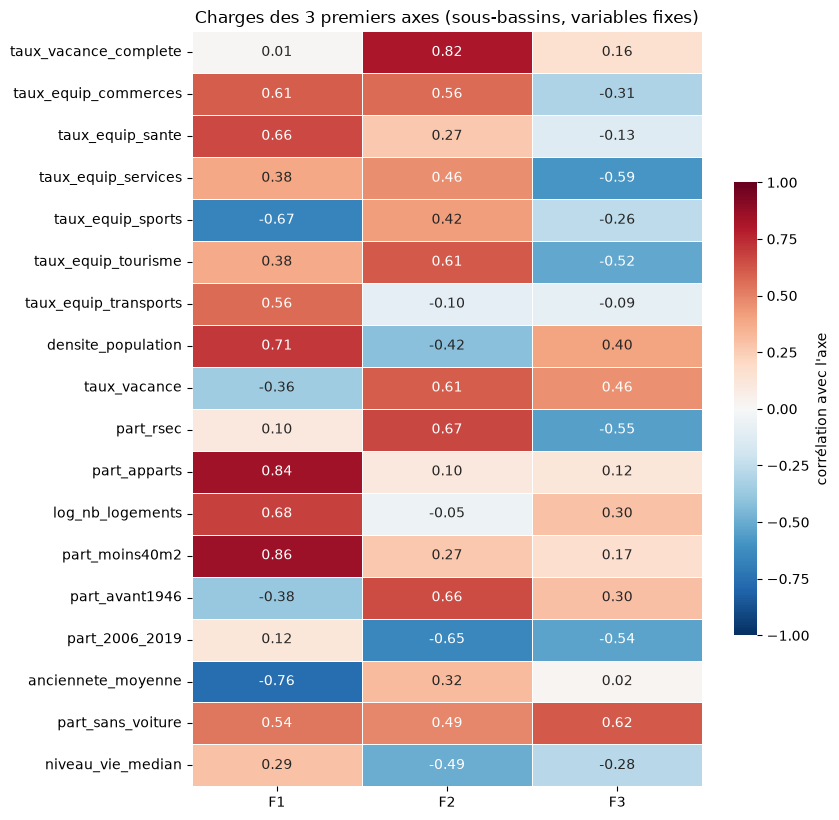

Communalité sur 3 axes, les 6 plus faibles :
taux_equip_transports    0.34
niveau_vie_median        0.41
taux_equip_sante         0.53
log_nb_logements         0.56
part_avant1946           0.66
anciennete_moyenne       0.68


In [28]:
# Orientation : chaque axe est rendu positif sur la variable qui le porte le plus
for k in range(K):
    if acp_complete.components_[k, np.argmax(np.abs(acp_complete.components_[k]))] < 0:
        acp_complete.components_[k] *= -1

AXES = [f"F{i + 1}" for i in range(K)]
charges = pd.DataFrame(acp_complete.components_[:K].T * np.sqrt(vp[:K]), index=STATIQUES, columns=AXES)
communalite = (charges ** 2).sum(axis=1)

fig, ax = plt.subplots(figsize=(8.5, 0.35 * len(STATIQUES) + 2))
sns.heatmap(charges, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", linewidths=0.5,
            cbar_kws={"label": "corrélation avec l'axe", "shrink": 0.6}, ax=ax)
ax.set_title(f"Charges des {K} premiers axes (sous-bassins, variables fixes)")
plt.tight_layout()
plt.show()

print(f"Communalité sur {K} axes, les 6 plus faibles :")
print(communalite.sort_values().head(6).round(2).to_string())

**Comment lire**
- **Charge** : corrélation entre une variable et un axe ; au-delà de 0,7 en valeur absolue, la variable porte l'axe. On nomme l'axe d'après ces variables.
- **Communalité faible** (sous 0,5) : la variable est mal résumée par les axes. Si elle est importante pour le prix, il faut la garder à part, en plus des axes.

### 12.5 Les axes et le niveau de prix des sous-bassins

Corrélation de Spearman entre les axes et log(prix) moyen du sous-bassin :
               F1    F2    F3
appartement  0.57 -0.27 -0.42
maison       0.73 -0.54 -0.43


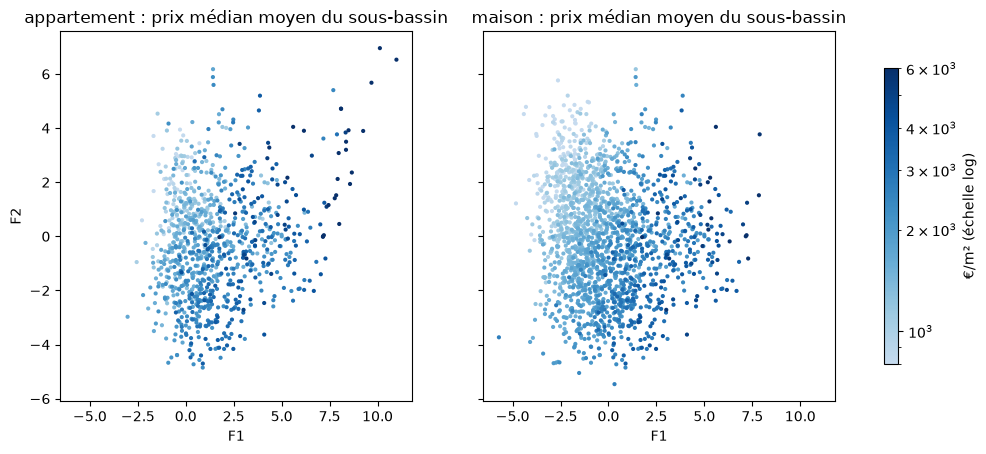

In [29]:
scores = pd.DataFrame(acp_complete.transform(Xz)[:, :K], index=zones.index, columns=AXES)

lp_zone = d.groupby(["sous_bassin_de_vie", "type_bien"])["lp"].mean().unstack()
print("Corrélation de Spearman entre les axes et log(prix) moyen du sous-bassin :")
print(pd.DataFrame({t: scores.corrwith(lp_zone[t], method="spearman") for t in lp_zone}).round(2).T.to_string())

bleus = plt.matplotlib.colors.LinearSegmentedColormap.from_list("bleus", plt.cm.Blues(np.linspace(0.25, 1, 256)))
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True, sharey=True)
for a, t in zip(ax, ["appartement", "maison"]):
    s = scores.join(lp_zone[t].rename("lp")).dropna().sort_values("lp")
    sc = a.scatter(s["F1"], s["F2"], c=np.exp(s["lp"]), cmap=bleus, norm=plt.matplotlib.colors.LogNorm(800, 6000),
                   s=9, edgecolors="none")
    a.set_title(f"{t} : prix médian moyen du sous-bassin")
    a.set_xlabel("F1")
ax[0].set_ylabel("F2")
cb = fig.colorbar(sc, ax=ax, shrink=0.8)
cb.set_label("€/m² (échelle log)")
plt.show()

**Comment lire** : mêmes repères de ρ que la section 6. Sur le nuage F1 × F2, un dégradé net de couleur indique que les deux premiers axes séparent bien les sous-bassins chers et bon marché ; un groupe isolé de points foncés signale des territoires à part (par exemple Paris).

### 12.6 La délinquance se résume-t-elle à un seul axe ?
Les taux de délinquance changent d'une année à l'autre : ACP sur une ligne par sous-bassin × année (lignes des maisons, années où tous les taux sont renseignés), taux passés en log(1 + x).

In [30]:
CRIME = [c for c in plat.columns if c.startswith("taux3_")]
cr = plat[(plat["type_bien"] == "maison") & plat[CRIME].notna().all(axis=1)][CRIME]
acp_crime = PCA().fit(StandardScaler().fit_transform(np.log1p(cr)))
correlations_crime = cr.corr("spearman").where(~np.eye(len(CRIME), dtype=bool))
print(f"{len(cr)} sous-bassins × années avec les {len(CRIME)} taux renseignés")
print("% de variance par axe :", (acp_crime.explained_variance_ratio_[:4] * 100).round(1).tolist())
print("Charges F1 :", dict(zip([c.replace("taux3_", "") for c in CRIME],
                               (acp_crime.components_[0] * np.sqrt(acp_crime.explained_variance_[0])).round(2))))
print("Corrélations de Spearman entre taux (min / médiane) :",
      np.round(np.nanmin(correlations_crime), 2), "/", np.round(np.nanmedian(correlations_crime), 2))

16015 sous-bassins × années avec les 7 taux renseignés
% de variance par axe : [43.6, 24.0, 13.8, 7.0]
Charges F1 : {'vols_vehicules': np.float64(0.84), 'vols_violents': np.float64(0.8), 'vols_sans_violence': np.float64(0.8), 'cambriolages': np.float64(0.47), 'stupefiants': np.float64(0.69), 'violences_intrafamiliales': np.float64(0.48), 'violences_sexuelles': np.float64(0.37)}
Corrélations de Spearman entre taux (min / médiane) : -0.05 / 0.28


**Comment lire** : si le premier axe capte moins de la moitié de la variance et que certains taux y chargent peu (vers 0,4), il n'existe pas un « niveau de délinquance » unique, mais plusieurs familles ; un indice unique perdrait une grande partie de l'information.

### 12.7 Ce que l'ACP coûte en prédiction
Cible : niveau de prix relatif du sous-bassin (log du prix moins la médiane nationale de l'année et du type de bien), moyenné sur les années avant la validation. Validation croisée en 5 groupes de sous-bassins : chaque sous-bassin est prévu par un modèle qui ne l'a pas vu.

In [31]:
d_rel = d.copy()
nat = d_rel.groupby(["type_bien", "annee"])["lp"].median().rename("lp_nat")
d_rel = d_rel.join(nat, on=["type_bien", "annee"])
d_rel["rel"] = d_rel["lp"] - d_rel["lp_nat"]
cible_zone = d_rel.groupby(["sous_bassin_de_vie", "type_bien"])["rel"].mean().unstack()


def arbre():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=20, random_state=0)


K8 = min(8, p)
modeles_cout = {
    f"OLS, {p} variables":       lambda: make_pipeline(StandardScaler(), LinearRegression()),
    f"Ridge, {p} variables":     lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    f"OLS, {K} axes ACP":        lambda: make_pipeline(StandardScaler(), PCA(K), LinearRegression()),
    f"OLS, {K8} axes ACP":       lambda: make_pipeline(StandardScaler(), PCA(K8), LinearRegression()),
    f"Boosting, {p} variables":  arbre,
    f"Boosting, {K} axes ACP":   lambda: make_pipeline(StandardScaler(), PCA(K), arbre()),
}
cv = KFold(5, shuffle=True, random_state=0)   # une ligne par sous-bassin : les groupes sont des sous-bassins
res = []
for t in ["appartement", "maison"]:
    y = cible_zone[t].dropna()
    Xm = zones.loc[y.index]
    for nom, f in modeles_cout.items():
        pred = cross_val_predict(f(), Xm, y, cv=cv)
        res.append({"type de bien": t, "modèle": nom,
                    "R²": 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                    "erreur médiane %": np.median(np.abs(np.expm1(pred - y))) * 100})
cout_acp = pd.DataFrame(res).pivot(index="modèle", columns="type de bien").round(3)
display(cout_acp.loc[list(modeles_cout)])

R²        erreur médiane %        
type de bien           appartement maison      appartement  maison
modèle                                                            
OLS, 18 variables            0.876  0.903           12.018   7.970
Ridge, 18 variables          0.876  0.903           11.880   7.936
OLS, 3 axes ACP              0.704  0.837           17.711  11.038
OLS, 8 axes ACP              0.862  0.882           12.654   9.152
Boosting, 18 variables       0.861  0.915           11.778   7.219
Boosting, 3 axes ACP         0.755  0.833           16.416  10.468

**Comment lire**
- **R²** et **erreur médiane %** : qualité de l'estimation du niveau d'un sous-bassin qu'aucun modèle n'a vu, à partir de ses seules caractéristiques.
- **Axes contre variables** : si les axes donnent un R² nettement plus bas, l'information laissée de côté par l'ACP contient du signal prix : pas d'ACP pour prédire.
- **Ridge égal à OLS** : la colinéarité ne nuit pas à la prédiction, seulement à la lecture des coefficients.
- **Boosting égal à OLS** : pas de gain des effets de seuil sur ce niveau moyen.
- Si une ACP entre un jour dans un modèle, elle doit être ajustée sur les seules données d'apprentissage (dans un `Pipeline`).

# Synthèse : historique des passages

Chaque passage correspond à un état de la table. On y garde les enseignements tirés, et la suite donnée à chaque action (complétée au passage suivant).

## Passage 1 : table complète, sans les ménages (31/10 au 03/11/2026)

**État de la table :** 28 450 lignes, 38 colonnes, prix 2015 à 2025 ; délinquance, LOVAC, équipements, densité, parc de logements, Filosofi, volume de ventes ; pas encore les ménages. Les analyses de la partie ACP complète (Gabrielle) ont été faites sur une version de travail de la table (43 604 lignes, 2014-2025, avec les nombres bruts), avant sa mise au format de la table de modélisation.

| Constat majeur | Preuve | Conséquence projet | Action | Suite donnée |
|---|---|---|---|---|
| La table compte une seule variable par information | 28 450 lignes, 38 colonnes ; délinquance en taux lissés sur 3 ans, équipements pour 10 000 habitants, densité, part des ménages couverts ; un seul nombre restant (`nb_ventes_n1`) | Les territoires de tailles différentes sont comparables | Fait dans le feature engineering | — |
| Peu de valeurs vides, toutes expliquées | Délinquance vide pour les prix 2015-2016 (17,4 %) ; LOVAC vide pour un sous-bassin (49069, 11 lignes) | La régression linéaire refuse les cases vides | Retirer ces lignes (ou les compléter) pour les modèles qui l'exigent | Fait : le masque de `commun.py` retire une seule fois les lignes à case vide, pour tous les modèles |
| 22 variables très asymétriques, avec des valeurs isolées réelles | Asymétrie > 1 ; valeurs isolées = centres touristiques, Paris | Une régression linéaire serait tirée par quelques territoires | Log pour la régression, le modèle hiérarchique et le réseau de neurones ; inutile pour les arbres | Décision d'équipe : log dans les notebooks de modélisation, pour les seuls modèles qui en ont besoin |
| Le prix N-1 donne presque tout le niveau ; les années d'apprentissage sont toutes en hausse | ρ = 0,99 avec le prix (2020-2023) ; évolution médiane des maisons +4,7 / +7,7 / +9,1 / +0,8 % de 2020 à 2023, baisse en 2024 | La prévision naïve est difficile à battre ; l'enjeu est l'évolution d'une année à l'autre | La naïve reste la référence | — |
| Le niveau des prix tient surtout aux territoires | Variance du log(prix) : 85 % (appartements) à 93 % (maisons) entre territoires, 3 à 5 % tendance commune, 2 à 12 % évolution propre | Les variables fixes n'expliquent que le niveau ; la tendance nationale n'est pas dans la table | Séparer niveau du territoire, tendance commune et résidu dans la modélisation | — |
| Trois couples de variables redondantes | Petits logements / suroccupation (0,88), sans voiture / parking (−0,84), vols sans violence / destructions (0,78) ; SHAP de la régression : une variable gardée au hasard, ou les deux opposées | Retirer `part_suroccupes`, `part_parking`, `taux3_destructions` ne change ni le R² ni l'erreur (+1 %) | Retirer ces 3 variables | Fait : retirées dans le feature engineering (03/11/2026) |
| Les prix suivent l'attractivité du parc et le niveau de vie ; la délinquance compte peu | Maisons : logements d'avant 1946 −0,76, vacance −0,73, ancienneté d'emménagement −0,71, niveau de vie 0,66 ; cambriolages, stupéfiants, destructions ≤ 0,18 | Variables à tester en priorité | — | — |
| Une variable de contrôle qualité mesure la ruralité | `part_logements_taux_impute` : ρ = −0,50 (maisons) et −0,47 (appartements) avec le prix | Elle ne décrit pas seulement la donnée | Hors modèle | Décision d'équipe : variables de contrôle qualité hors modèle, pour l'analyse des erreurs seulement |
| Les variables du territoire expliquent l'essentiel du niveau des prix | Régression linéaire sans prix N-1, validée sur 2024 : R² 0,80 (maisons) et 0,86 (appartements), sans surapprentissage ; erreur de 329 et 476 €/m² | Elles disent où les prix sont hauts ou bas, pas comment ils évoluent | Le prix N-1 et les variables de marché restent indispensables pour l'évolution | — |
| La forêt aléatoire prévoit mieux que la régression linéaire | Validation 2024 sans prix N-1 : erreur de 221 contre 329 €/m² (maisons), 350 contre 476 €/m² (appartements) | Effets de seuil et interactions | Comparer régression et modèles à arbres à la modélisation | Repris dans la feuille de route (du plus simple au plus complexe) |
| La densité servait d'étiquette « Paris » | SHAP de la forêt ; avant le correctif, chaque arrondissement avait la densité de sa ville | — | Densité par arrondissement | Fait : superficie réelle de chaque arrondissement (bloc 1 de la préparation) |
| Après le correctif, les arrondissements forment un groupe à part | 45 densités distinctes (Paris 8 271 à 37 873 hab/km², Lyon 7 106 à 18 603, Marseille 1 119 à 22 818) ; tous les sous-bassins au-dessus de 5 000 hab/km² sont des arrondissements ; asymétrie 8,4, puis 1,5 en log10 | Effet de levier sur un modèle linéaire non transformé | Log de la densité ; analyse de sensibilité avec et sans arrondissements | Log : décision d'équipe ci-dessus |
| 7 variables ne comptent dans aucun modèle | Part de l'importance SHAP < 2 % dans les 4 modèles : `part_indicateurs_estimes`, `part_menages_couverts`, `taux3_stupefiants`, `taux3_cambriolages`, `taux3_vols_violents`, `taux_equip_sante`, `taux_vacance_complete` | Elles alourdissent les modèles sans les améliorer | Candidates au retrait, à confirmer à la modélisation | — |
| L'ACP résume le territoire mais fait perdre du signal prix | Version simple : 3 axes = 63 % ; forêt sur les 3 axes 329 €/m² d'erreur contre 187 avec les 27 variables (maisons), 578 contre 309 (appartements). Version complète : KMO 0,86, 4 axes (Kaiser et Horn) = 81 % ; niveau de vie mal résumé (communalité 0,43) ; 4 axes : R² 0,91 → 0,82 (maisons) | Pas d'ACP pour prédire | Axes réservés à l'interprétation et aux variables de contrôle des tests d'hypothèses ; régression interprétable : axes + niveau de vie | — |
| La délinquance ne se résume pas à un seul axe | Premier axe = 47 % de la variance des 8 taux ; cambriolages et violences chargent peu (≈ 0,4) | Un indice unique perdrait la moitié de l'information | Garder les taux séparés | — |

## Passage 2 : redondances retirées, ménages ajoutés (04/11/2026)

**État de la table :** 28 450 lignes, 41 colonnes. Changements : 3 variables redondantes retirées ; 5 variables des ménages ajoutées (recensements 2019-2022, une valeur par année) ; `BV2022` ajouté (identifiant du bassin de vie, pour le test contre la naïve) ; densité calculée avec la superficie réelle de chaque arrondissement.

| Constat majeur | Preuve | Conséquence projet | Action | Suite donnée |
|---|---|---|---|---|
| La table reste propre | 28 450 lignes, 41 colonnes, index unique ; valeurs vides seulement pour la délinquance des prix 2015-2016 (17,4 %) ; ménages sans case vide | Rien ne change pour le masque commun | — | — |
| Un trio redondant entre deux sources | `taille_menage` (logement) / `taille_moyenne_menage` (ménages) ρ = 0,99 ; avec `taux_personnes_seules_pct_men` −0,93 et −0,92. SHAP de la régression : les deux tailles en tête, avec des effets opposés | Le trio dégrade la prévision : avec les deux tailles, R² de validation des maisons 0,74 (0,80 en apprentissage) et erreur de 438 €/m² ; sans elles, 0,79 et 331 €/m² (−24 %). Appartements : 520 → 476 €/m² (−8 %) | Retirer `taille_menage` et `taille_moyenne_menage` ; garder `taux_personnes_seules_pct_men` | Fait : retirées dans le feature engineering |
| Une variable des ménages à passer en log | Familles monoparentales : asymétrie 1,07, sans zéro ; les autres variables des ménages sont symétriques | Même règle que pour les autres variables | Ajouter `part_familles_monoparentales_pct_fam` à la liste des variables en log | Fait dans le notebook H3b ; à reporter dans `modelisation_template.ipynb`. Depuis le 05/11/2026, la liste est calculée par ce notebook à chaque passage (section 3) |
| La densité ne sert plus d'étiquette « Paris » | SHAP de la forêt : densité 22e pour les appartements. Paris est reconnu par d'autres variables : très forte part de ménages sans voiture (+3 700 à +4 800 €/m²), très faible part de logements récents (+1 900 à +3 000 €/m²) | Les paquets isolés regroupent probablement les arrondissements parisiens | — | — |
| Sans le trio, mêmes résultats d'ensemble qu'au passage 1 | Régression : R² 0,79 (maisons) et 0,86 (appartements), erreur de 331 et 476 €/m², sans surapprentissage. Forêt : R² 0,88 et 0,91, erreur de 220 et 353 €/m² | Les conclusions du passage 1 tiennent | — | — |
| 8 variables ne comptent dans aucun modèle | Part de l'importance SHAP < 2 % dans les 4 modèles : `part_indicateurs_estimes`, `part_menages_couverts`, `taux3_stupefiants`, `taux3_cambriolages`, `taux_equip_sante`, `taux_vacance_complete`, `part_familles_monoparentales_pct_fam`, `part_couples_sans_enfants_pct_fam`. Juste au-dessus : vols violents (2,2 %) | Les ménages apportent peu une fois le trio réduit | Candidates au retrait, à confirmer à la modélisation (erreur avec et sans) | — |
| Une variable de contrôle qualité pèse dans un modèle | `part_logements_taux_impute` : 4,7 % dans la régression des maisons, indice du caractère rural | Elle mesure en partie le territoire | Hors modèle (décision d'équipe) | Appliqué par le template de modélisation |